# Detection of Mechanical Faults in Rotating Machinery Using FFT-Based Vibration Signal Analysis

**MTE 3121 Digital Signal Processing - Mini Project** (Dept. of Mechatronics, MIT Manipal)

Team: Dhanush Chittoory (240929286), Polimera Devashish Reddy (240929196),
Bhuvan Chand Rayani (240929236), Yash Ralhan (240929268)

This notebook is the same pipeline as `vibration_analysis.py`. It is a
**simulation-only** study: the vibration signals are synthetic, so every
conclusion applies to the chosen signal model and is *not* validation on real
machinery. No result value is assumed in advance; every number below is
produced by the code.

## Step 0 - Setup, configuration and signal model
All parameters live in one `CFG` dictionary. The sampling setup
(fs = 5000 Hz, T = 2 s, N = 10000) gives a bin spacing fs/N = 0.5 Hz, and every
injected frequency (25, 50, 100, 150, 1113, 1200, 1287 Hz ...) is an integer
multiple of 0.5 Hz, so each tone sits exactly on an FFT bin and there is no
spectral leakage for the main tones.

In [1]:
import csv
import sys
import time
from pathlib import Path

import matplotlib
import numpy as np
from scipy import signal, stats
from scipy.interpolate import CubicSpline

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # no GUI needed when run as a script
import matplotlib.pyplot as plt  # noqa: E402

np.random.seed(42)  # reproducible noise realisations

BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
FIG_DIR = BASE / "figures"
RES_DIR = BASE / "results"
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

CFG = {
    "fs": 5000.0,             # sampling frequency [Hz]
    "T": 2.0,                 # duration [s]
    "f_r": 50.0,              # shaft rotation frequency [Hz] (3000 RPM)
    "sigma": 0.25,            # Gaussian noise standard deviation
    "healthy_amps": (1.0, 0.3, 0.1),   # amplitudes at 1x, 2x, 3x
    "imb_a1": 2.5,            # imbalance: 1x amplitude
    "mis_a2": 1.2,            # misalignment: 2x amplitude
    "mis_a3": 0.8,            # misalignment: 3x amplitude
    "mis_a_half": 0.15,       # misalignment: small 0.5x component
    "f_res": 1200.0,          # bearing resonance carrier [Hz]
    "f_fault": 87.0,          # bearing fault (modulation) frequency [Hz]
    "a_res": 0.5,             # carrier amplitude
    "mod_depth": 0.8,         # AM depth m
    "lp_cut": 400.0,          # low-pass cut-off [Hz]
    "lp_order": 4,
    "bp_band": (1000.0, 1400.0),  # band-pass edges [Hz]
    "bp_order": 4,
    "peak_height": 0.05,      # find_peaks: minimum amplitude
    "peak_prom": 0.03,        # find_peaks: minimum prominence
    "amp_tol": 0.02,          # tolerance for amplitude verification
    "mc_runs": 50,            # Monte Carlo runs per class
    "sweep_sigmas": [0.1, 0.25, 0.5, 1.0, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0],
    "clf": {                  # toy classifier thresholds (midpoints of the
        "bearing_sideband": 0.10,   # nominal healthy/fault amplitudes)
        "imb_a1": 1.75,
        "mis_a2": 0.75,
        "mis_a3": 0.45,
    },
    "leak_freq": 50.3,        # off-bin tone for the leakage demo [Hz]
    # --- Part B (extended studies) ---
    "n_balls": 9,             # bearing geometry: typical 6205-type deep-groove
    "d_ball": 7.94,           # ball diameter [mm]
    "d_pitch": 39.04,         # pitch diameter [mm]
    "contact_deg": 0.0,       # contact angle [deg]
    "imp_amp": 3.0,           # impulse-response amplitude
    "imp_tau": 0.0005,        # resonance decay time constant [s]
    "imp_jitter": 0.01,       # random arrival-time jitter (fraction of period)
    "welch_nperseg": (2000, 1000),
    "onset_time": 1.0,        # imbalance starts at this time [s]
    "speed_ramp": (50.0, 56.0),   # shaft speed drifts f0 -> f1 over T [Hz]
    "stft_lens": (200, 500, 1000),
    "stft_hop": 100,
    "sev_amps": [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0],
    "ext_runs": 20,           # runs per point in Part B averages
}
CFG["N"] = int(CFG["fs"] * CFG["T"])
CFG["df"] = CFG["fs"] / CFG["N"]
CASES = ["Healthy", "Imbalance", "Misalignment", "Bearing fault"]
COLORS = {"Healthy": "#4d4d4d", "Imbalance": "#D55E00",
          "Misalignment": "#0072B2", "Bearing fault": "#009E73",
          "filtered": "#CC79A7"}

plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "legend.fontsize": 8, "axes.grid": True, "grid.alpha": 0.3,
    "lines.linewidth": 1.0, "figure.dpi": 100, "savefig.dpi": 200,
    "savefig.bbox": "tight",
})

LOG_LINES = []


def log(msg=""):
    """Print a line and keep a copy for results/summary.txt."""
    print(msg)
    LOG_LINES.append(str(msg))


def save_fig(fig, name):
    """Save a figure to figures/ at 200 dpi (and show it in a notebook)."""
    fig.savefig(FIG_DIR / name, dpi=200)
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)
    log(f"[saved] figures/{name}")

### Signal generators
`make_healthy`, `make_imbalance`, `make_misalignment` and `make_bearing`
each return the signal. `noise=False` returns the clean (noise-free) signal, which
we later use as a reference for SNR. Each noisy call draws a fresh Gaussian
noise realisation with the same sigma.

In [2]:
def time_axis(cfg=CFG):
    """Return the sample times t[n] = n / fs for n = 0 .. N-1."""
    return np.arange(cfg["N"]) / cfg["fs"]


def harmonic_signal(t, cfg, a1, a2, a3, a_half=0.0):
    """Sum of shaft harmonics: a_half at 0.5x, a1/a2/a3 at 1x/2x/3x."""
    fr = cfg["f_r"]
    x = (a1 * np.sin(2 * np.pi * fr * t)
         + a2 * np.sin(2 * np.pi * 2 * fr * t)
         + a3 * np.sin(2 * np.pi * 3 * fr * t))
    if a_half:
        x = x + a_half * np.sin(2 * np.pi * 0.5 * fr * t)
    return x


def add_noise(x, sigma):
    """Add zero-mean white Gaussian noise of standard deviation sigma."""
    return x + np.random.normal(0.0, sigma, size=x.shape)


def make_healthy(cfg=CFG, noise=True, sigma=None):
    """Healthy machine: 1x, 2x, 3x shaft harmonics (+ noise)."""
    t = time_axis(cfg)
    x = harmonic_signal(t, cfg, *cfg["healthy_amps"])
    return add_noise(x, cfg["sigma"] if sigma is None else sigma) if noise else x


def make_imbalance(cfg=CFG, noise=True, sigma=None):
    """Imbalance: the 1x amplitude is raised to cfg['imb_a1']."""
    t = time_axis(cfg)
    _, a2, a3 = cfg["healthy_amps"]
    x = harmonic_signal(t, cfg, cfg["imb_a1"], a2, a3)
    return add_noise(x, cfg["sigma"] if sigma is None else sigma) if noise else x


def make_misalignment(cfg=CFG, noise=True, sigma=None):
    """Misalignment: strong 2x and 3x plus a small 0.5x component."""
    t = time_axis(cfg)
    a1 = cfg["healthy_amps"][0]
    x = harmonic_signal(t, cfg, a1, cfg["mis_a2"], cfg["mis_a3"],
                        cfg["mis_a_half"])
    return add_noise(x, cfg["sigma"] if sigma is None else sigma) if noise else x


def bearing_term(t, cfg):
    """Bearing fault: A(1 + m sin(2 pi f_fault t)) sin(2 pi f_res t)."""
    return (cfg["a_res"] * (1 + cfg["mod_depth"]
                            * np.sin(2 * np.pi * cfg["f_fault"] * t))
            * np.sin(2 * np.pi * cfg["f_res"] * t))


def make_bearing(cfg=CFG, noise=True, sigma=None):
    """Simplified outer-race bearing fault: healthy signal + AM resonance."""
    t = time_axis(cfg)
    x = harmonic_signal(t, cfg, *cfg["healthy_amps"]) + bearing_term(t, cfg)
    return add_noise(x, cfg["sigma"] if sigma is None else sigma) if noise else x


MAKERS = {"Healthy": make_healthy, "Imbalance": make_imbalance,
          "Misalignment": make_misalignment, "Bearing fault": make_bearing}


def injected_components(case, cfg=CFG):
    """Analytical list of (frequency, amplitude, label) injected per case.

    AM theory: A(1+m sin(wf t)) sin(wr t) = A sin(wr t)
    + (A m / 2)[cos((wr-wf)t) - cos((wr+wf)t)], so each sideband has A*m/2.
    """
    fr = cfg["f_r"]
    a1, a2, a3 = cfg["healthy_amps"]
    if case == "Imbalance":
        a1 = cfg["imb_a1"]
    comps = [(fr, a1, "1x"), (2 * fr, a2, "2x"), (3 * fr, a3, "3x")]
    if case == "Misalignment":
        comps = [(0.5 * fr, cfg["mis_a_half"], "0.5x"), (fr, a1, "1x"),
                 (2 * fr, cfg["mis_a2"], "2x"), (3 * fr, cfg["mis_a3"], "3x")]
    if case == "Bearing fault":
        side = cfg["a_res"] * cfg["mod_depth"] / 2
        comps += [(cfg["f_res"] - cfg["f_fault"], side, "resonance - f_fault"),
                  (cfg["f_res"], cfg["a_res"], "bearing resonance"),
                  (cfg["f_res"] + cfg["f_fault"], side, "resonance + f_fault")]
    return comps

### Spectrum and helper functions
The single-sided amplitude spectrum is `2/N * |X[k]|`; the DC bin (and the
Nyquist bin for even N) are not doubled, so they are divided by 2 again. With a
window w the normalisation `2/sum(w)` keeps tone amplitudes correct (coherent
gain correction). For the rectangular window sum(w) = N.

In [3]:
def amplitude_spectrum(x, fs, window=None):
    """Return (freqs, single-sided amplitude spectrum) of x.

    window: None (rectangular) or any scipy.signal.get_window name, e.g. 'hann'.
    """
    n = len(x)
    w = np.ones(n) if window is None else signal.get_window(window, n)
    amp = 2.0 * np.abs(np.fft.rfft(x * w)) / np.sum(w)
    amp[0] /= 2.0                  # DC bin is not mirrored
    if n % 2 == 0:
        amp[-1] /= 2.0             # Nyquist bin is not mirrored
    return np.fft.rfftfreq(n, d=1.0 / fs), amp


def amp_at(amp, f, df):
    """Largest amplitude within +/-1 bin of frequency f."""
    k = int(round(f / df))
    return amp[max(k - 1, 0):k + 2].max()


def snr_db(ref, x):
    """SNR [dB] of x with respect to the reference signal ref."""
    return 10 * np.log10(np.mean(ref ** 2) / np.mean((x - ref) ** 2))


def time_stats(x):
    """Return RMS, peak, crest factor and kurtosis (Pearson, normal = 3)."""
    rms = np.sqrt(np.mean(x ** 2))
    peak = np.max(np.abs(x))
    return rms, peak, peak / rms, stats.kurtosis(x, fisher=False)


def label_peak(f, case, cfg=CFG):
    """Return (label, injected amplitude) for a peak at f, else ('unassigned', nan)."""
    for fk, ak, lab in injected_components(case, cfg):
        if abs(f - fk) <= 1.0:
            return lab, ak
    return "unassigned", float("nan")


def design_filters(cfg=CFG):
    """Return (sos_lp, sos_bp) Butterworth filters in second-order sections."""
    sos_lp = signal.butter(cfg["lp_order"], cfg["lp_cut"], btype="low",
                           fs=cfg["fs"], output="sos")
    sos_bp = signal.butter(cfg["bp_order"], cfg["bp_band"], btype="band",
                           fs=cfg["fs"], output="sos")
    return sos_lp, sos_bp


def classify(amp, cfg=CFG):
    """Toy rule-based classifier using 1x/2x/3x and bearing sideband amplitudes."""
    c, df, fr = cfg["clf"], cfg["df"], cfg["f_r"]
    side = min(amp_at(amp, cfg["f_res"] - cfg["f_fault"], df),
               amp_at(amp, cfg["f_res"] + cfg["f_fault"], df))
    a1, a2, a3 = (amp_at(amp, k * fr, df) for k in (1, 2, 3))
    if side > c["bearing_sideband"]:
        return "Bearing fault"
    if a2 > c["mis_a2"] and a3 > c["mis_a3"]:
        return "Misalignment"
    if a1 > c["imb_a1"]:
        return "Imbalance"
    return "Healthy"

## Step 1 - Generate signals and time-domain analysis
One noisy realisation of each case (same sigma, independent noise). We plot a
0.1 s window (5 shaft revolutions) and the full 2 s record, and compute RMS, peak,
crest factor and kurtosis. The point: these scalar time-domain indicators do not
say *which* fault is present, which is the motivation for the frequency domain.

MTE 3121 DSP mini project - FFT-based vibration fault analysis
fs = 5000 Hz, T = 2.0 s, N = 10000, resolution fs/N = 0.5 Hz, f_r = 50.0 Hz (3000 RPM), sigma = 0.25, seed = 42

Time-domain statistics (noisy signals)
Case                RMS    Peak   Crest  Kurtosis
Healthy           0.784   1.939   2.473     1.911
Imbalance         1.803   3.339   1.852     1.533
Misalignment      1.269   3.400   2.679     2.984
Bearing fault     0.882   2.407   2.730     2.297


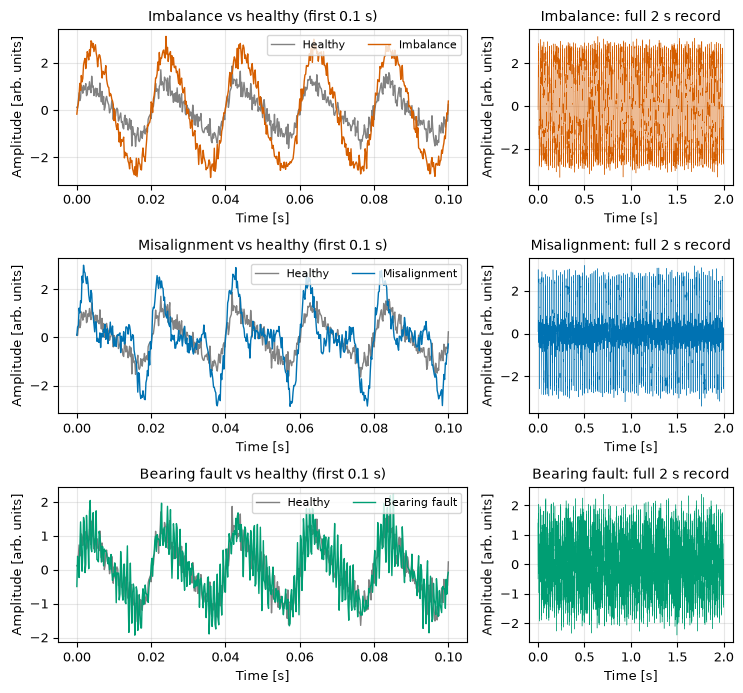

[saved] figures/01_time_domain.png


In [4]:
t = time_axis()
fs, N, fr, df = CFG["fs"], CFG["N"], CFG["f_r"], CFG["df"]
log("=" * 70)
log("MTE 3121 DSP mini project - FFT-based vibration fault analysis")
log(f"fs = {fs:.0f} Hz, T = {CFG['T']} s, N = {N}, resolution fs/N = {df} Hz, "
    f"f_r = {fr} Hz ({fr * 60:.0f} RPM), sigma = {CFG['sigma']}, seed = 42")
log("=" * 70)

signals = {case: MAKERS[case]() for case in CASES}      # noisy
clean = {case: MAKERS[case](noise=False) for case in CASES}

log("\nTime-domain statistics (noisy signals)")
log(f"{'Case':<15}{'RMS':>8}{'Peak':>8}{'Crest':>8}{'Kurtosis':>10}")
tstats = {}
for case in CASES:
    tstats[case] = time_stats(signals[case])
    log(f"{case:<15}{tstats[case][0]:>8.3f}{tstats[case][1]:>8.3f}"
        f"{tstats[case][2]:>8.3f}{tstats[case][3]:>10.3f}")

win = t <= 0.1
fig, axes = plt.subplots(3, 2, figsize=(7.5, 7.0),
                         gridspec_kw={"width_ratios": [2, 1]})
for row, case in enumerate(CASES[1:]):
    ax = axes[row, 0]
    ax.plot(t[win], signals["Healthy"][win], color=COLORS["Healthy"],
            alpha=0.7, label="Healthy")
    ax.plot(t[win], signals[case][win], color=COLORS[case], label=case)
    ax.set_title(f"{case} vs healthy (first 0.1 s)")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Amplitude [arb. units]")
    ax.legend(loc="upper right", ncol=2)
    ax = axes[row, 1]
    ax.plot(t, signals[case], color=COLORS[case], lw=0.3)
    ax.set_title(f"{case}: full 2 s record")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Amplitude [arb. units]")
fig.tight_layout()
save_fig(fig, "01_time_domain.png")

## Step 2 - Pre-processing: Butterworth filtering
* **Low-pass, 400 Hz, order 4** for imbalance and misalignment. The signal content
  is at 25-150 Hz (0.5x-3x), so 400 Hz keeps all of it with margin (>2.5x the
  highest tone) while rejecting white noise above 400 Hz. For white noise
  spread over 0-2500 Hz the expected noise-power reduction is
  10 log10(2500/400) = 7.96 dB.
* **Band-pass, 1000-1400 Hz, order 4** for the bearing case. It is centred on the
  1200 Hz resonance, and the 400 Hz width is larger than the 2 x 87 = 174 Hz span
  of the two modulation sidebands (1113, 1287 Hz), so they pass. The shaft
  harmonics are intentionally removed so the resonance band can be inspected
  alone. Same expected noise reduction (7.96 dB).
* Filters are designed as second-order sections (`sos`) for numerical stability and
  applied with `sosfiltfilt` (forward-backward, zero phase). Forward-backward
  filtering squares the magnitude response, so the effective response is |H|^2.


Filter design: Butterworth, sos output, sosfiltfilt (zero phase)
  Low-pass  : order 4, fc = 400.0 Hz
  Band-pass : order 4, band = (1000.0, 1400.0) Hz


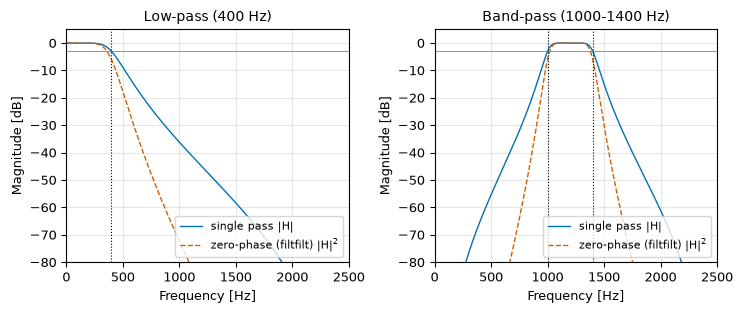

[saved] figures/02_filter_response.png

Noise reduction from filtering (noise realisation of Step 1)
Case           Filter     SNR before  SNR after  Noise rms before   after  Reduction
Imbalance      low-pass      17.05 dB    25.52 dB            0.2502  0.0943     8.48 dB
Misalignment   low-pass      14.02 dB    22.41 dB            0.2478  0.0943     8.40 dB
Bearing fault  band-pass     -5.70 dB    12.67 dB            0.2511  0.0944     8.50 dB
Theoretical white-noise power reduction for fc = 400 Hz: 7.96 dB


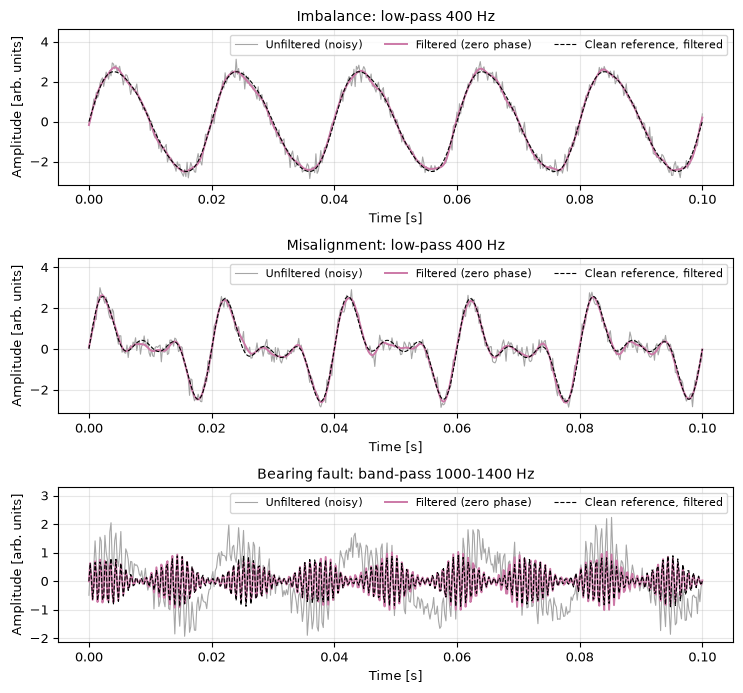

[saved] figures/03_filtering_time.png


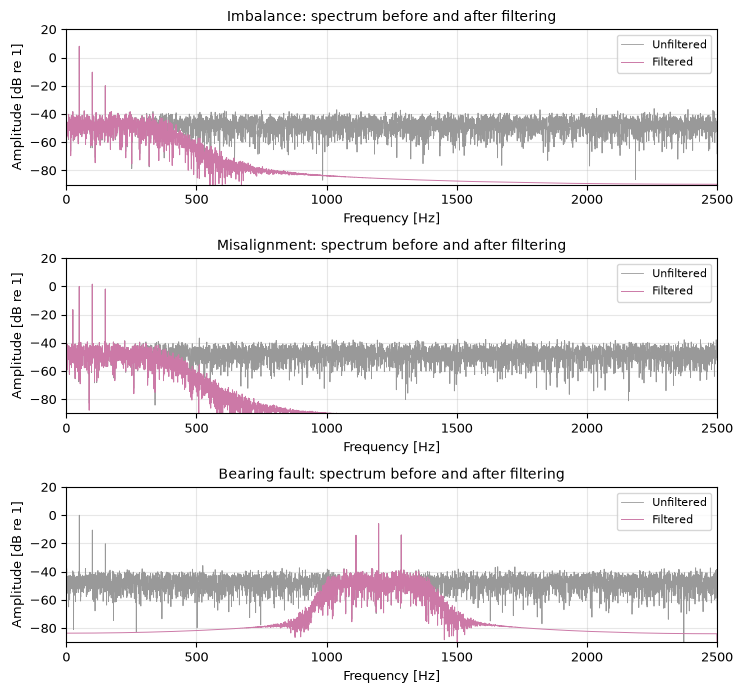

[saved] figures/04_filtering_spectrum.png


In [5]:
sos_lp, sos_bp = design_filters()
log("\nFilter design: Butterworth, sos output, sosfiltfilt (zero phase)")
log(f"  Low-pass  : order {CFG['lp_order']}, fc = {CFG['lp_cut']} Hz")
log(f"  Band-pass : order {CFG['bp_order']}, band = {CFG['bp_band']} Hz")

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2))
for ax, sos, name, marks in [
        (axes[0], sos_lp, "Low-pass (400 Hz)", [CFG["lp_cut"]]),
        (axes[1], sos_bp, "Band-pass (1000-1400 Hz)", list(CFG["bp_band"]))]:
    w_, h_ = signal.sosfreqz(sos, worN=4096, fs=fs)
    mag = 20 * np.log10(np.maximum(np.abs(h_), 1e-8))
    ax.plot(w_, mag, color="#0072B2", label="single pass |H|")
    ax.plot(w_, 2 * mag, color="#D55E00", ls="--",
            label="zero-phase (filtfilt) |H|$^2$")
    for m in marks:
        ax.axvline(m, color="k", ls=":", lw=0.8)
    ax.axhline(-3, color="gray", lw=0.6)
    ax.set_ylim(-80, 5)
    ax.set_xlim(0, fs / 2)
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("Magnitude [dB]")
    ax.set_title(name)
    ax.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "02_filter_response.png")

filt_cases = {"Imbalance": sos_lp, "Misalignment": sos_lp,
              "Bearing fault": sos_bp}
filtered = {c: signal.sosfiltfilt(s, signals[c]) for c, s in filt_cases.items()}
filtered_clean = {c: signal.sosfiltfilt(s, clean[c])
                  for c, s in filt_cases.items()}

# SNR definitions: for the low-pass cases the signal of interest is the whole
# clean waveform. For the bearing case it is the bearing term alone (the shaft
# harmonics are interference that the band-pass removes).
log("\nNoise reduction from filtering (noise realisation of Step 1)")
log(f"{'Case':<15}{'Filter':<10}{'SNR before':>11}{'SNR after':>11}"
    f"{'Noise rms before':>18}{'after':>8}{'Reduction':>11}")
noise_red = {}
theory_db = 10 * np.log10((fs / 2) / CFG["lp_cut"])
for case, sos in filt_cases.items():
    if case == "Bearing fault":
        s_ref = clean[case] - clean["Healthy"]
        s_ref_f = signal.sosfiltfilt(sos, s_ref)
        fname = "band-pass"
    else:
        s_ref, s_ref_f = clean[case], filtered_clean[case]
        fname = "low-pass"
    n_before = signals[case] - clean[case]
    n_after = filtered[case] - filtered_clean[case]
    before = snr_db(s_ref, s_ref + (signals[case] - s_ref))
    after = snr_db(s_ref_f, filtered[case])
    rms_b, rms_a = np.std(n_before), np.std(n_after)
    red = 20 * np.log10(rms_b / rms_a)
    noise_red[case] = (before, after, rms_b, rms_a, red)
    log(f"{case:<15}{fname:<10}{before:>9.2f} dB{after:>9.2f} dB"
        f"{rms_b:>18.4f}{rms_a:>8.4f}{red:>9.2f} dB")
log(f"Theoretical white-noise power reduction for fc = 400 Hz: {theory_db:.2f} dB")

fig, axes = plt.subplots(3, 1, figsize=(7.5, 7.0))
for ax, case in zip(axes, CASES[1:]):
    ax.plot(t[win], signals[case][win], color="0.65", lw=0.8,
            label="Unfiltered (noisy)")
    ax.plot(t[win], filtered[case][win], color=COLORS["filtered"], lw=1.4,
            label="Filtered (zero phase)")
    ax.plot(t[win], filtered_clean[case][win], color="k", lw=0.8, ls="--",
            label="Clean reference, filtered")
    kind = "band-pass 1000-1400 Hz" if case == "Bearing fault" \
        else "low-pass 400 Hz"
    ax.set_title(f"{case}: {kind}")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Amplitude [arb. units]")
    ax.set_ylim(ax.get_ylim()[0], ax.get_ylim()[1] * 1.35)
    ax.legend(loc="upper right", ncol=3)
fig.tight_layout()
save_fig(fig, "03_filtering_time.png")

fig, axes = plt.subplots(3, 1, figsize=(7.5, 7.0))
for ax, case in zip(axes, CASES[1:]):
    f_, a_raw = amplitude_spectrum(signals[case], fs)
    _, a_filt = amplitude_spectrum(filtered[case], fs)
    ax.plot(f_, 20 * np.log10(a_raw + 1e-12), color="0.6", lw=0.6,
            label="Unfiltered")
    ax.plot(f_, 20 * np.log10(a_filt + 1e-12), color=COLORS["filtered"],
            lw=0.7, label="Filtered")
    ax.set_ylim(-90, 20)
    ax.set_xlim(0, fs / 2)
    ax.set_title(f"{case}: spectrum before and after filtering")
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("Amplitude [dB re 1]")
    ax.legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "04_filtering_spectrum.png")

## Step 3 - FFT analysis
`np.fft.rfft` / `rfftfreq` give the single-sided amplitude spectrum. Dashed lines
mark 1x, 2x and 3x (50, 100, 150 Hz). Because all tones are integer multiples of
0.5 Hz, they land exactly on bins and the rectangular window is exact for them.

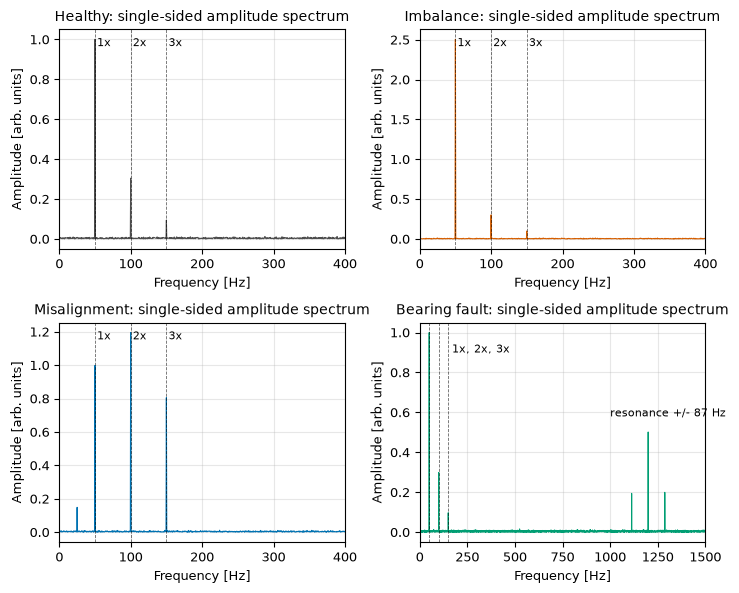

[saved] figures/05_spectra_all.png

Spectral leakage demo (unit-amplitude tone, no noise)
  50.0 Hz (bin-aligned), rectangular : peak = 1.0000
  50.3 Hz (off-bin), rectangular  : peak = 0.7556  (scalloping error 24.4 %)
  50.3 Hz (off-bin), Hann         : peak = 0.9010  (scalloping error 9.9 %)
  Mean far-from-peak leakage level (300-2000 Hz): rectangular -79.5 dB, Hann -198.5 dB


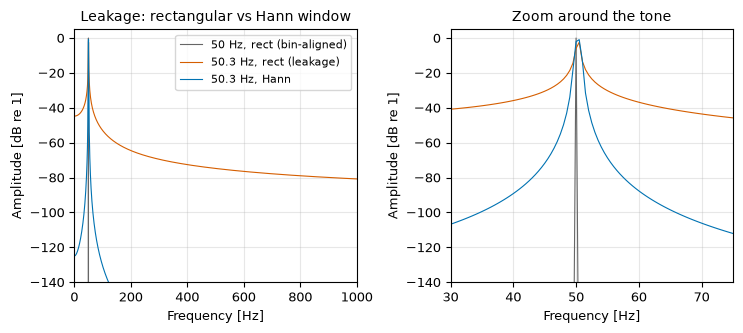

[saved] figures/06_window_leakage.png

Frequency-resolution demo: tones at 50 Hz and 53 Hz (3 Hz apart)
  N =   500: resolution   10 Hz -> 1 resolved peak(s) at [50.0] Hz
  N =  1000: resolution    5 Hz -> 1 resolved peak(s) at [50.0] Hz
  N = 10000: resolution  0.5 Hz -> 2 resolved peak(s) at [50.0, 53.0] Hz


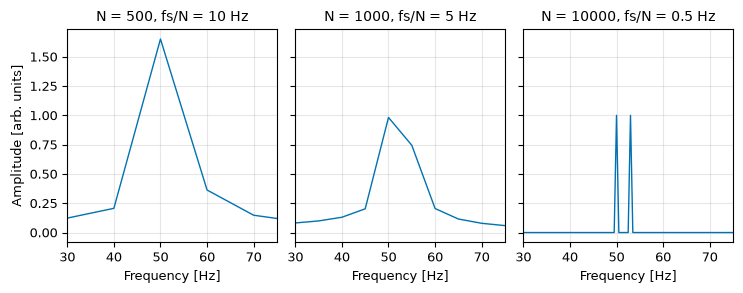

[saved] figures/07_resolution_vs_N.png


In [6]:
spectra = {}
for case in CASES:
    f_axis, spectra[case] = amplitude_spectrum(signals[case], fs)

fig, axes = plt.subplots(2, 2, figsize=(7.5, 6.0))
for ax, case in zip(axes.ravel(), CASES):
    ax.plot(f_axis, spectra[case], color=COLORS[case], lw=0.8)
    for k in (1, 2, 3):
        ax.axvline(k * fr, color="k", ls="--", lw=0.6, alpha=0.6)
    if case == "Bearing fault":
        ax.set_xlim(0, 1500)
        ax.annotate("1x, 2x, 3x", (170, 0.9), fontsize=8)
        ax.annotate("resonance +/- 87 Hz", (1000, 0.58), fontsize=8)
    else:
        ax.set_xlim(0, 400)
        for k in (1, 2, 3):
            ax.annotate(f"{k}x", (k * fr + 3, ax.get_ylim()[1] * 0.92),
                        fontsize=8)
    ax.set_title(f"{case}: single-sided amplitude spectrum")
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("Amplitude [arb. units]")
fig.tight_layout()
save_fig(fig, "05_spectra_all.png")

# --- Optional demo 1: spectral leakage, rectangular vs Hann window ---------
f_leak = CFG["leak_freq"]
x_al = np.sin(2 * np.pi * fr * t)
x_off = np.sin(2 * np.pi * f_leak * t)
f_, a_al = amplitude_spectrum(x_al, fs)
_, a_rect = amplitude_spectrum(x_off, fs)
_, a_hann = amplitude_spectrum(x_off, fs, window="hann")
log("\nSpectral leakage demo (unit-amplitude tone, no noise)")
log(f"  {fr} Hz (bin-aligned), rectangular : peak = {a_al.max():.4f}")
log(f"  {f_leak} Hz (off-bin), rectangular  : peak = {a_rect.max():.4f}  "
    f"(scalloping error {100 * (1 - a_rect.max()):.1f} %)")
log(f"  {f_leak} Hz (off-bin), Hann         : peak = {a_hann.max():.4f}  "
    f"(scalloping error {100 * (1 - a_hann.max()):.1f} %)")
far = (f_ > 300) & (f_ < 2000)
log(f"  Mean far-from-peak leakage level (300-2000 Hz): rectangular "
    f"{20 * np.log10(a_rect[far].mean()):.1f} dB, Hann "
    f"{20 * np.log10(a_hann[far].mean() + 1e-12):.1f} dB")

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4))
for ax, xlim in zip(axes, [(0, 1000), (30, 75)]):
    ax.plot(f_, 20 * np.log10(a_al + 1e-12), color="0.4", lw=0.8,
            label=f"{fr:.0f} Hz, rect (bin-aligned)")
    ax.plot(f_, 20 * np.log10(a_rect + 1e-12), color="#D55E00", lw=0.8,
            label=f"{f_leak} Hz, rect (leakage)")
    ax.plot(f_, 20 * np.log10(a_hann + 1e-12), color="#0072B2", lw=0.8,
            label=f"{f_leak} Hz, Hann")
    ax.set_xlim(*xlim)
    ax.set_ylim(-140, 5)
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("Amplitude [dB re 1]")
axes[0].set_title("Leakage: rectangular vs Hann window")
axes[1].set_title("Zoom around the tone")
axes[0].legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "06_window_leakage.png")

# --- Optional demo 2: effect of record length N on resolution --------------
x2 = np.sin(2 * np.pi * 50 * t) + np.sin(2 * np.pi * 53 * t)
fig, axes = plt.subplots(1, 3, figsize=(7.5, 3.0), sharey=True)
log("\nFrequency-resolution demo: tones at 50 Hz and 53 Hz (3 Hz apart)")
for ax, n in zip(axes, [500, 1000, 10000]):
    f_n, a_n = amplitude_spectrum(x2[:n], fs)
    ax.plot(f_n, a_n, color="#0072B2")
    ax.set_xlim(30, 75)
    ax.set_title(f"N = {n}, fs/N = {fs / n:g} Hz")
    ax.set_xlabel("Frequency [Hz]")
    pk, _ = signal.find_peaks(a_n, prominence=0.2)
    log(f"  N = {n:>5}: resolution {fs / n:>4g} Hz -> "
        f"{len(pk)} resolved peak(s) at {[float(f_n[p]) for p in pk]} Hz")
axes[0].set_ylabel("Amplitude [arb. units]")
fig.tight_layout()
save_fig(fig, "07_resolution_vs_N.png")

## Step 4 - Peak detection and comparison
`scipy.signal.find_peaks` (height >= 0.05, prominence >= 0.03) finds the dominant
peaks. Each peak is matched to the *injected* component within 1 Hz, and the
measured amplitude is compared with the injected amplitude. This is the
correctness check: peak frequencies must match to within the 0.5 Hz bin
spacing, and amplitudes should differ only by noise.


Detected peaks (find_peaks, height >= 0.05, prominence >= 0.03)
Case            Freq [Hz]  Amplitude  Injected  Label
Healthy              50.0     1.0008     1.000  1x
Healthy             100.0     0.3048     0.300  2x
Healthy             150.0     0.0947     0.100  3x
Imbalance            50.0     2.5056     2.500  1x
Imbalance           100.0     0.3023     0.300  2x
Imbalance           150.0     0.1004     0.100  3x
Misalignment         25.0     0.1491     0.150  0.5x
Misalignment         50.0     0.9988     1.000  1x
Misalignment        100.0     1.1953     1.200  2x
Misalignment        150.0     0.8056     0.800  3x
Bearing fault        50.0     0.9998     1.000  1x
Bearing fault       100.0     0.2993     0.300  2x
Bearing fault       150.0     0.0976     0.100  3x
Bearing fault      1113.0     0.1946     0.200  resonance - f_fault
Bearing fault      1200.0     0.5018     0.500  bearing resonance
Bearing fault      1287.0     0.1997     0.200  resonance + f_fault
[saved] result

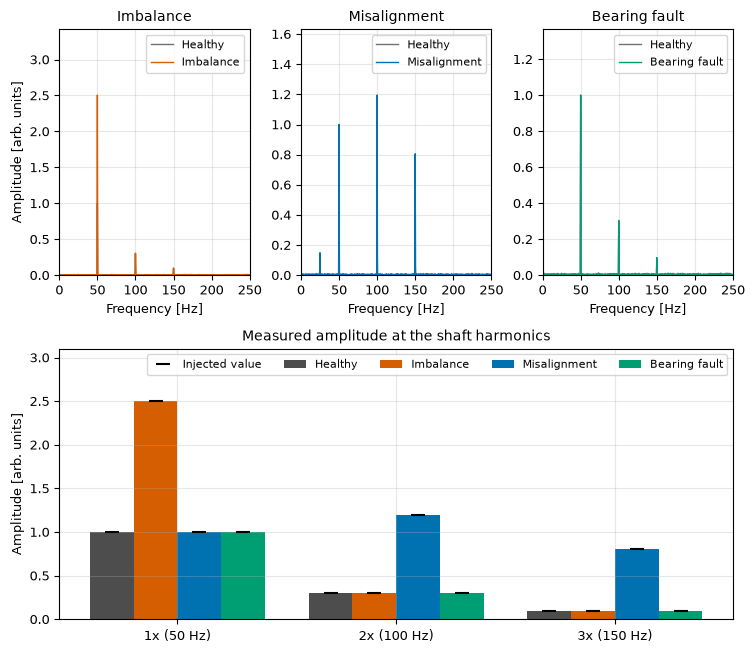

[saved] figures/08_comparison.png

Envelope analysis (band-pass 1000-1400 Hz -> Hilbert envelope -> FFT)
  Dominant envelope-spectrum peak: 87.0 Hz, amplitude 0.379 (theory A*m = 0.400, noise biases it slightly)
  Raw-spectrum amplitude near 87 Hz: 0.0067 (no visible component: the fault rate is only in the envelope)


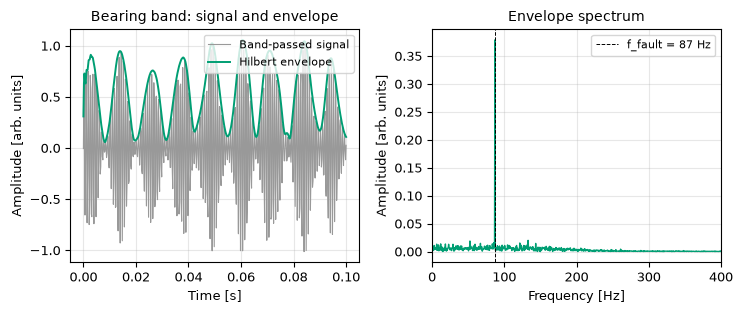

[saved] figures/09_envelope_bearing.png


In [7]:
rows = []
log("\nDetected peaks (find_peaks, height >= "
    f"{CFG['peak_height']}, prominence >= {CFG['peak_prom']})")
log(f"{'Case':<15}{'Freq [Hz]':>10}{'Amplitude':>11}{'Injected':>10}  Label")
for case in CASES:
    pk, _ = signal.find_peaks(spectra[case], height=CFG["peak_height"],
                              prominence=CFG["peak_prom"])
    for p in pk:
        lab, inj = label_peak(f_axis[p], case)
        rows.append((case, float(f_axis[p]), float(spectra[case][p]), inj, lab))
        inj_s = f"{inj:.3f}" if not np.isnan(inj) else "-"
        log(f"{case:<15}{f_axis[p]:>10.1f}{spectra[case][p]:>11.4f}"
            f"{inj_s:>10}  {lab}")
with open(RES_DIR / "peak_table.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["case", "peak_frequency_Hz", "measured_amplitude",
                "injected_amplitude", "label"])
    w.writerows([(c, f"{f:.1f}", f"{a:.4f}",
                  "" if np.isnan(i) else f"{i:.3f}", lab)
                 for c, f, a, i, lab in rows])
log("[saved] results/peak_table.csv")

# Verification: every injected component must appear as a detected peak at
# the right frequency (within one bin) with the right amplitude.
log("\nVerification against injected values")
log(f"{'Case':<15}{'Component':<22}{'f inj':>8}{'f det':>8}"
    f"{'A inj':>8}{'A meas':>8}{'Err':>8}  Result")
all_ok = True
for case in CASES:
    detected = [(f, a) for c, f, a, _, _ in rows if c == case]
    for fk, ak, lab in injected_components(case):
        match = [(f, a) for f, a in detected if abs(f - fk) <= df]
        if not match:
            log(f"{case:<15}{lab:<22}{fk:>8.1f}{'-':>8}{ak:>8.3f}{'-':>8}"
                f"{'-':>8}  FAIL (not detected)")
            all_ok = False
            continue
        f_d, a_d = match[0]
        ok = abs(f_d - fk) <= df and abs(a_d - ak) <= CFG["amp_tol"]
        all_ok &= ok
        log(f"{case:<15}{lab:<22}{fk:>8.1f}{f_d:>8.1f}{ak:>8.3f}{a_d:>8.3f}"
            f"{a_d - ak:>+8.3f}  {'OK' if ok else 'FAIL'}")
    extra = [r for r in rows if r[0] == case and r[4] == "unassigned"]
    if extra:
        all_ok = False
        log(f"{case:<15}UNEXPECTED peaks: {[(r[1], round(r[2], 3)) for r in extra]}")
log(f"Overall verification (|df| <= {df} Hz, |dA| <= {CFG['amp_tol']}): "
    f"{'PASS' if all_ok else 'FAIL'}")

# Comparison figure: overlays + bar chart of 1x/2x/3x amplitudes
fig = plt.figure(figsize=(7.5, 6.6))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.1])
for j, case in enumerate(CASES[1:]):
    ax = fig.add_subplot(gs[0, j])
    ax.plot(f_axis, spectra["Healthy"], color=COLORS["Healthy"], lw=1.0,
            alpha=0.8, label="Healthy")
    ax.plot(f_axis, spectra[case], color=COLORS[case], lw=1.0, label=case)
    ax.set_xlim(0, 250)
    ax.set_title(case)
    ax.set_xlabel("Frequency [Hz]")
    if j == 0:
        ax.set_ylabel("Amplitude [arb. units]")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
    ax.legend(loc="upper right")
ax = fig.add_subplot(gs[1, :])
width = 0.2
for i, case in enumerate(CASES):
    meas = [amp_at(spectra[case], k * fr, df) for k in (1, 2, 3)]
    inj = [dict((lab, a) for _, a, lab in injected_components(case))[f"{k}x"]
           for k in (1, 2, 3)]
    xpos = np.arange(3) + (i - 1.5) * width
    ax.bar(xpos, meas, width, color=COLORS[case], label=case)
    ax.plot(xpos, inj, "k_", ms=10, mew=1.5,
            label="Injected value" if i == 0 else None)
ax.set_xticks(range(3))
ax.set_xticklabels(["1x (50 Hz)", "2x (100 Hz)", "3x (150 Hz)"])
ax.set_ylabel("Amplitude [arb. units]")
ax.set_ylim(0, 3.1)
ax.set_title("Measured amplitude at the shaft harmonics")
ax.legend(ncol=5, loc="upper right")
fig.tight_layout()
save_fig(fig, "08_comparison.png")

# Bonus: envelope spectrum of the bearing band (shows the 87 Hz fault rate)
env = np.abs(signal.hilbert(filtered["Bearing fault"]))
f_env, a_env = amplitude_spectrum(env - env.mean(), fs)
sel = (f_env > 10) & (f_env < 400)
i_env = np.argmax(a_env * sel)
raw_at_87 = amp_at(spectra["Bearing fault"], CFG["f_fault"], df)
log("\nEnvelope analysis (band-pass 1000-1400 Hz -> Hilbert envelope -> FFT)")
log(f"  Dominant envelope-spectrum peak: {f_env[i_env]:.1f} Hz, amplitude "
    f"{a_env[i_env]:.3f} (theory A*m = "
    f"{CFG['a_res'] * CFG['mod_depth']:.3f}, noise biases it slightly)")
log(f"  Raw-spectrum amplitude near {CFG['f_fault']:.0f} Hz: {raw_at_87:.4f} "
    "(no visible component: the fault rate is only in the envelope)")

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2))
axes[0].plot(t[win], filtered["Bearing fault"][win], color="0.6", lw=0.8,
             label="Band-passed signal")
axes[0].plot(t[win], env[win], color=COLORS["Bearing fault"], lw=1.4,
             label="Hilbert envelope")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Amplitude [arb. units]")
axes[0].set_title("Bearing band: signal and envelope")
axes[0].legend(loc="upper right")
axes[1].plot(f_env, a_env, color=COLORS["Bearing fault"])
axes[1].set_xlim(0, 400)
axes[1].axvline(CFG["f_fault"], color="k", ls="--", lw=0.7,
                label=f"f_fault = {CFG['f_fault']:.0f} Hz")
axes[1].set_xlabel("Frequency [Hz]")
axes[1].set_ylabel("Amplitude [arb. units]")
axes[1].set_title("Envelope spectrum")
axes[1].legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "09_envelope_bearing.png")

## Step 5 - Toy rule-based classifier (Monte Carlo)
Simple threshold rules on the spectral amplitudes. **This is a toy demonstration on
simulated data**: the thresholds are midpoints between the nominal amplitudes of the
model we ourselves defined, so high accuracy is expected and says nothing about
real machines. 50 fresh noise realisations per class at sigma = 0.25.

Rules (in order): both bearing sidebands > 0.10 -> bearing; 2x > 0.75 and
3x > 0.45 -> misalignment; 1x > 1.75 -> imbalance; otherwise healthy.


Toy classifier, 50 runs per class, sigma = 0.25 (simulated data only)
True \ Predicted         Healthy      Imbalance   Misalignment  Bearing fault
Healthy                       50              0              0              0
Imbalance                      0             50              0              0
Misalignment                   0              0             50              0
Bearing fault                  0              0              0             50
Overall accuracy: 100.0 %


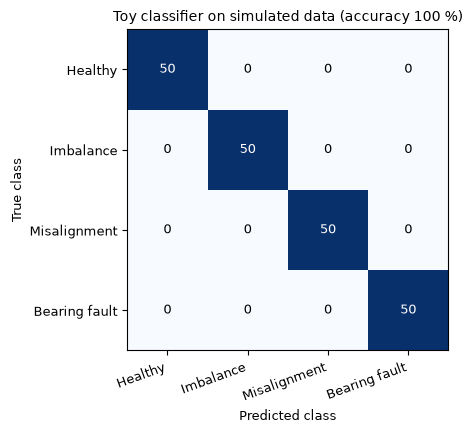

[saved] figures/10_confusion_matrix.png


In [8]:
runs = CFG["mc_runs"]
conf = np.zeros((4, 4), dtype=int)
for i, case in enumerate(CASES):
    for _ in range(runs):
        _, a_mc = amplitude_spectrum(MAKERS[case](), fs)
        conf[i, CASES.index(classify(a_mc))] += 1
acc = np.trace(conf) / conf.sum()
log(f"\nToy classifier, {runs} runs per class, sigma = {CFG['sigma']} "
    "(simulated data only)")
log(f"{'True \\ Predicted':<17}" + "".join(f"{c:>15}" for c in CASES))
for i, case in enumerate(CASES):
    log(f"{case:<17}" + "".join(f"{v:>15d}" for v in conf[i]))
log(f"Overall accuracy: {100 * acc:.1f} %")

fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(conf, cmap="Blues", vmin=0, vmax=runs)
ax.grid(False)
ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_xticklabels(CASES, rotation=20, ha="right")
ax.set_yticklabels(CASES)
for i in range(4):
    for j in range(4):
        ax.text(j, i, conf[i, j], ha="center", va="center",
                color="white" if conf[i, j] > runs / 2 else "black")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(f"Toy classifier on simulated data (accuracy {100 * acc:.0f} %)")
fig.tight_layout()
save_fig(fig, "10_confusion_matrix.png")

## Step 6 - Robustness: sweep the noise level
For each sigma we run 50 noise realisations per case. A signature peak counts as
*detected* when its amplitude exceeds the largest spectral bin elsewhere (excluding
+/-2 bins around every injected component). We also track the toy classifier
accuracy with its thresholds held fixed.


Noise sweep (50 runs per point): detection rate of each signature peak
Signature                             0.1   0.25    0.5      1      2      3      4      6      8     12
Imbalance 1x (2.5)                   1.00   1.00   1.00   1.00   1.00   1.00   1.00   1.00   1.00   1.00
Misalign. 2x (1.2)                   1.00   1.00   1.00   1.00   1.00   1.00   1.00   1.00   1.00   1.00
Misalign. 3x (0.8)                   1.00   1.00   1.00   1.00   1.00   1.00   1.00   1.00   1.00   0.60
Misalign. 0.5x (0.15)                1.00   1.00   1.00   1.00   0.86   0.46   0.02   0.00   0.02   0.00
Bearing sideband 1113 Hz (0.2)       1.00   1.00   1.00   1.00   1.00   0.72   0.20   0.08   0.04   0.00
Bearing sideband 1287 Hz (0.2)       1.00   1.00   1.00   1.00   0.98   0.70   0.30   0.04   0.02   0.00
Toy classifier accuracy              1.00   1.00   1.00   1.00   1.00   0.98   0.83   0.42   0.28   0.25
(columns are the noise sigma)
  Imbalance 1x (2.5): first sigma with detection rate < 95

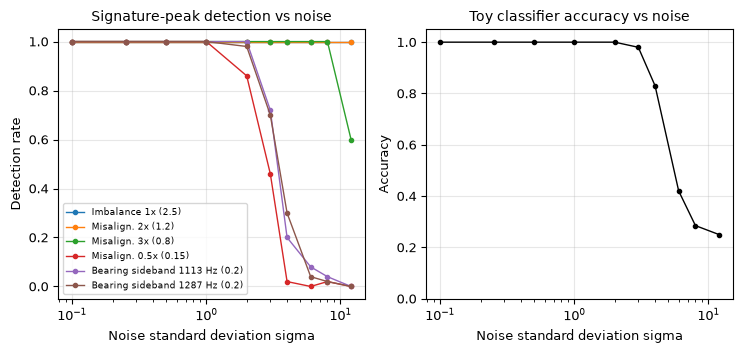

[saved] figures/11_noise_sweep.png


In [9]:
signatures = [("Imbalance 1x (2.5)", "Imbalance", CFG["f_r"]),
              ("Misalign. 2x (1.2)", "Misalignment", 2 * CFG["f_r"]),
              ("Misalign. 3x (0.8)", "Misalignment", 3 * CFG["f_r"]),
              ("Misalign. 0.5x (0.15)", "Misalignment", 0.5 * CFG["f_r"]),
              ("Bearing sideband 1113 Hz (0.2)", "Bearing fault",
               CFG["f_res"] - CFG["f_fault"]),
              ("Bearing sideband 1287 Hz (0.2)", "Bearing fault",
               CFG["f_res"] + CFG["f_fault"])]


def detection_rate(case, f_sig, sigma, n_runs):
    """Fraction of runs where the peak at f_sig exceeds all other bins."""
    hits = 0
    for _ in range(n_runs):
        _, a = amplitude_spectrum(MAKERS[case](sigma=sigma), fs)
        mask = np.ones(len(a), dtype=bool)
        for fk, _, _ in injected_components(case):
            k = int(round(fk / df))
            mask[max(k - 2, 0):k + 3] = False
        hits += amp_at(a, f_sig, df) > a[mask].max()
    return hits / n_runs


sig_list = CFG["sweep_sigmas"]
det = np.array([[detection_rate(c, f, s, runs) for s in sig_list]
                for _, c, f in signatures])
acc_sweep = []
for s in sig_list:
    correct = 0
    for case in CASES:
        for _ in range(runs):
            _, a = amplitude_spectrum(MAKERS[case](sigma=s), fs)
            correct += classify(a) == case
    acc_sweep.append(correct / (runs * len(CASES)))

log(f"\nNoise sweep ({runs} runs per point): detection rate of each signature peak")
log(f"{'Signature':<34}" + "".join(f"{s:>7g}" for s in sig_list))
for (name, _, _), row in zip(signatures, det):
    log(f"{name:<34}" + "".join(f"{v:>7.2f}" for v in row))
log(f"{'Toy classifier accuracy':<34}"
    + "".join(f"{v:>7.2f}" for v in acc_sweep))
log("(columns are the noise sigma)")
for (name, _, _), row in zip(signatures, det):
    bad = [s for s, v in zip(sig_list, row) if v < 0.95]
    log(f"  {name}: first sigma with detection rate < 95 %: "
        f"{bad[0] if bad else 'none in sweep'}")

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6))
for (name, _, _), row in zip(signatures, det):
    axes[0].plot(sig_list, row, marker="o", ms=3, label=name)
axes[0].set_xscale("log")
axes[0].set_xlabel("Noise standard deviation sigma")
axes[0].set_ylabel("Detection rate")
axes[0].set_title("Signature-peak detection vs noise")
axes[0].legend(fontsize=6.5, loc="lower left")
axes[1].plot(sig_list, acc_sweep, marker="o", ms=3, color="k")
axes[1].set_xscale("log")
axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel("Noise standard deviation sigma")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Toy classifier accuracy vs noise")
fig.tight_layout()
save_fig(fig, "11_noise_sweep.png")

## Step 7 - Statistics over 50 noise realisations
The tables in Steps 1-4 use a single noise realisation per case. Here every case
is regenerated 50 times (fresh noise, same sigma) and each metric is reported
as mean +/- standard deviation: time-domain indicators, spectral amplitudes at
the injected frequencies, and the filtering SNR gain. (This step runs last so it
does not change the random draws used by the earlier steps.)

In [10]:
def filter_metrics(case, x):
    """Return (SNR before, SNR after, noise reduction) in dB for one noisy x."""
    sos = filt_cases[case]
    if case == "Bearing fault":
        s_ref = clean[case] - clean["Healthy"]
    else:
        s_ref = clean[case]
    s_ref_f = signal.sosfiltfilt(sos, s_ref)
    x_f = signal.sosfiltfilt(sos, x)
    n_f = x_f - signal.sosfiltfilt(sos, clean[case])
    return (snr_db(s_ref, x), snr_db(s_ref_f, x_f),
            20 * np.log10(np.std(x - clean[case]) / np.std(n_f)))


mc = {}
for case in CASES:
    ts_runs, amp_runs, filt_runs = [], [], []
    comps = injected_components(case)
    for _ in range(runs):
        x = MAKERS[case]()
        _, a = amplitude_spectrum(x, fs)
        ts_runs.append(time_stats(x))
        amp_runs.append([amp_at(a, fk, df) for fk, _, _ in comps])
        if case in filt_cases:
            filt_runs.append(filter_metrics(case, x))
    mc[case] = (np.array(ts_runs), np.array(amp_runs), np.array(filt_runs))

log(f"\nMonte Carlo statistics: {runs} noise realisations per case, "
    f"sigma = {CFG['sigma']} (mean +/- std)")
log(f"\nTime-domain indicators")
log(f"{'Case':<15}{'RMS':>16}{'Peak':>16}{'Crest':>16}{'Kurtosis':>16}")
for case in CASES:
    m, s = mc[case][0].mean(axis=0), mc[case][0].std(axis=0, ddof=1)
    log(f"{case:<15}" + "".join(f"{a:>10.3f}+/-{b:.3f}" for a, b in zip(m, s)))

log("\nSpectral amplitude at each injected frequency")
log(f"{'Case':<15}{'Component':<22}{'Injected':>9}{'Mean':>9}{'Std':>9}"
    f"{'Bias':>9}")
mc_rows = []
for case in CASES:
    amps = mc[case][1]
    for j, (fk, ak, lab) in enumerate(injected_components(case)):
        m, s = amps[:, j].mean(), amps[:, j].std(ddof=1)
        mc_rows.append((case, lab, fk, ak, m, s))
        log(f"{case:<15}{lab:<22}{ak:>9.3f}{m:>9.4f}{s:>9.4f}{m - ak:>+9.4f}")
log(f"(theory: amplitude std per bin ~ sigma*sqrt(2/N) = "
    f"{CFG['sigma'] * np.sqrt(2 / N):.4f}; bias is the mean error, "
    "close to zero)")

log("\nFiltering performance")
log(f"{'Case':<15}{'SNR before [dB]':>20}{'SNR after [dB]':>20}"
    f"{'Noise reduction [dB]':>24}")
for case in filt_cases:
    m, s = mc[case][2].mean(axis=0), mc[case][2].std(axis=0, ddof=1)
    log(f"{case:<15}" + "".join(f"{a:>13.2f}+/-{b:.2f}" for a, b in
                                zip(m[:2], s[:2]))
        + f"{m[2]:>17.2f}+/-{s[2]:.2f}")

with open(RES_DIR / "mc_amplitudes.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["case", "component", "frequency_Hz", "injected_amplitude",
                "mean_measured", "std_measured", f"runs={runs}"])
    w.writerows([(c, lab, f"{f:.1f}", f"{a:.3f}", f"{m:.4f}", f"{s:.4f}", "")
                 for c, lab, f, a, m, s in mc_rows])
log("[saved] results/mc_amplitudes.csv")


Monte Carlo statistics: 50 noise realisations per case, sigma = 0.25 (mean +/- std)

Time-domain indicators
Case                        RMS            Peak           Crest        Kurtosis
Healthy             0.783+/-0.003     1.960+/-0.087     2.504+/-0.113     1.896+/-0.011
Imbalance           1.799+/-0.002     3.340+/-0.087     1.857+/-0.048     1.530+/-0.003
Misalignment        1.271+/-0.002     3.303+/-0.097     2.600+/-0.076     2.978+/-0.010
Bearing fault       0.882+/-0.002     2.540+/-0.097     2.880+/-0.109     2.303+/-0.015

Spectral amplitude at each injected frequency
Case           Component              Injected     Mean      Std     Bias
Healthy        1x                        1.000   0.9999   0.0040  -0.0001
Healthy        2x                        0.300   0.2999   0.0036  -0.0001
Healthy        3x                        0.100   0.0992   0.0040  -0.0008
Imbalance      1x                        2.500   2.4995   0.0029  -0.0005
Imbalance      2x                        0

# Part B - Extended studies
Everything above is the core project committed to in the synopsis. The steps
below are extra studies in the same simulation framework: a more realistic
impulsive bearing model with real bearing frequencies, averaged (Welch)
spectra, a short-time Fourier transform for a non-stationary fault, a
drifting shaft speed with order tracking, a filter comparison, a severity
sweep, combined faults and cross-checks of the FFT itself.
They run after the core steps, with their own seed, so the core results do not change.

In [11]:
np.random.seed(42)
log("\n" + "=" * 70)
log("PART B - extended studies (seed reset to 42)")
log("=" * 70)
EXT_RUNS = CFG["ext_runs"]


PART B - extended studies (seed reset to 42)


## Step 8 - Real bearing frequencies and an impulsive bearing model
For a rolling-element bearing with n balls, ball diameter d, pitch diameter D
and contact angle phi, rotating at f_r (outer race fixed):

* BPFO = (n/2) f_r (1 - (d/D) cos phi)  (ball pass frequency, outer race)
* BPFI = (n/2) f_r (1 + (d/D) cos phi)  (ball pass frequency, inner race)
* BSF = (D/2d) f_r (1 - ((d/D) cos phi)^2),  FTF = (f_r/2)(1 - (d/D) cos phi)

The geometry used (9 balls, d = 7.94 mm, D = 39.04 mm, phi = 0) is typical of a
6205-type deep-groove bearing; these are assumed catalogue-style values, not
measured data. An outer-race defect makes each ball strike the defect once per
BPFO period, exciting a decaying structural resonance (1200 Hz here):
x(t) = sum_k A exp(-(t - t_k)/tau) sin(2 pi f_res (t - t_k)) for t >= t_k, with
t_k = (k + jitter * randn) / BPFO. BPFO is generally **not** a multiple of the
0.5 Hz bin spacing, so leakage is discussed below.

In [12]:
def bearing_frequencies(f_r, n_balls, d_ball, d_pitch, contact_deg=0.0):
    """Return a dict with FTF, BPFO, BPFI and BSF [Hz] for a rolling bearing."""
    ratio = d_ball / d_pitch * np.cos(np.radians(contact_deg))
    return {"FTF": 0.5 * f_r * (1 - ratio),
            "BPFO": 0.5 * n_balls * f_r * (1 - ratio),
            "BPFI": 0.5 * n_balls * f_r * (1 + ratio),
            "BSF": 0.5 * f_r * (d_pitch / d_ball) * (1 - ratio ** 2)}


def impulsive_bearing_term(t, f_fault, cfg, jitter):
    """Train of decaying resonance bursts arriving at f_fault with jitter."""
    fs_ = 1.0 / (t[1] - t[0])
    n_imp = int(np.floor(t[-1] * f_fault)) + 1
    t_k = (np.arange(n_imp) + jitter * np.random.randn(n_imp)) / f_fault
    span = int(10 * cfg["imp_tau"] * fs_)
    x = np.zeros_like(t)
    for tk in t_k:
        i0 = max(int(np.ceil(tk * fs_)), 0)
        seg = t[i0:i0 + span] - tk
        x[i0:i0 + span] += (cfg["imp_amp"] * np.exp(-seg / cfg["imp_tau"])
                            * np.sin(2 * np.pi * cfg["f_res"] * seg))
    return x


def make_bearing_impulsive(cfg=CFG, noise=True, sigma=None, f_fault=None,
                           jitter=None):
    """Healthy harmonics + impulsive outer-race fault at BPFO (+ noise)."""
    t_ = time_axis(cfg)
    if f_fault is None:
        f_fault = bearing_frequencies(cfg["f_r"], cfg["n_balls"],
                                      cfg["d_ball"], cfg["d_pitch"],
                                      cfg["contact_deg"])["BPFO"]
    jit = cfg["imp_jitter"] if jitter is None else jitter
    x = (harmonic_signal(t_, cfg, *cfg["healthy_amps"])
         + impulsive_bearing_term(t_, f_fault, cfg, jit))
    return add_noise(x, cfg["sigma"] if sigma is None else sigma) if noise else x


def envelope_spectrum(x, sos, fs_, window=None):
    """Band-pass x, take the Hilbert envelope, return its amplitude spectrum."""
    env = np.abs(signal.hilbert(signal.sosfiltfilt(sos, x)))
    return amplitude_spectrum(env - env.mean(), fs_, window)


Bearing geometry: n = 9, d = 7.94 mm, D = 39.04 mm, contact angle = 0.0 deg, f_r = 50 Hz
Frequency   Order (x f_r)        Hz
FTF                0.3983     19.92
BPFO               3.5848    179.24
BPFI               5.4152    270.76
BSF                2.3567    117.84
BPFO is 358.478 bins of 0.5 Hz: not bin-aligned (nearest bin 179.0 Hz)

Impulsive bearing model: envelope analysis (band-pass 1000-1400 Hz)
  Dominant envelope-spectrum peak: 179.0 Hz (BPFO = 179.24 Hz), amplitude 0.151
  Median envelope-spectrum floor (20-1000 Hz): 0.0007
  Envelope amplitude near BPFO                  179.24 Hz: 0.1510
  Envelope amplitude near 2 x BPFO              358.48 Hz: 0.0049
  Envelope amplitude near 3 x BPFO              537.72 Hz: 0.0014
  Envelope amplitude near BPFI (not injected)   270.76 Hz: 0.0047
  Raw spectrum amplitude near BPFO: 0.0887 (visible here too: the simulated bursts are broadband; real impacts are usually masked at low frequency, hence envelope analysis)

Kurtosis / crest f

Aligned f=179.0 Hz, no jitter            0.2257       0.2251


BPFO=179.24 Hz, no jitter                0.1477       0.1920
BPFO=179.24 Hz, jitter 1 %               0.1491       0.1935
BPFO=179.24 Hz, jitter 3 %               0.1508       0.1965


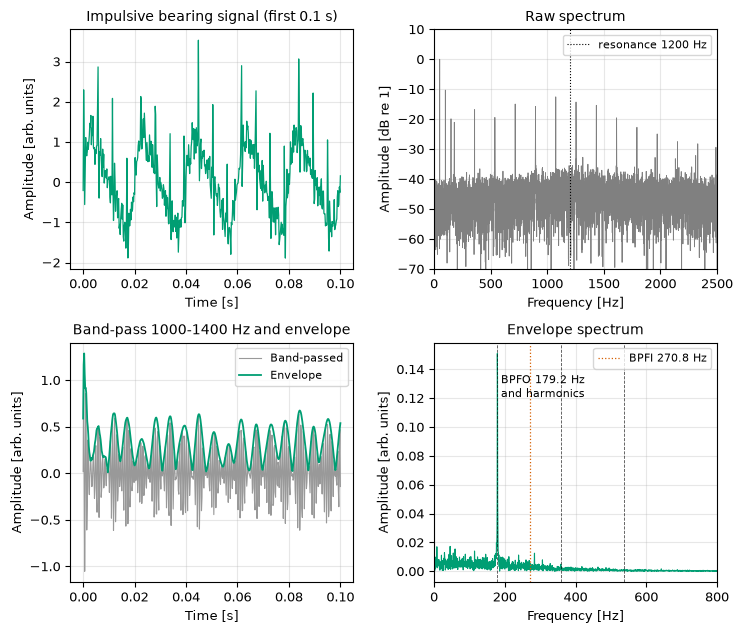

[saved] figures/12_impulsive_bearing.png


In [13]:
bf = bearing_frequencies(fr, CFG["n_balls"], CFG["d_ball"], CFG["d_pitch"],
                         CFG["contact_deg"])
BPFO, BPFI = bf["BPFO"], bf["BPFI"]
log(f"\nBearing geometry: n = {CFG['n_balls']}, d = {CFG['d_ball']} mm, "
    f"D = {CFG['d_pitch']} mm, contact angle = {CFG['contact_deg']} deg, "
    f"f_r = {fr:.0f} Hz")
log(f"{'Frequency':<10}{'Order (x f_r)':>15}{'Hz':>10}")
for k_, v_ in bf.items():
    log(f"{k_:<10}{v_ / fr:>15.4f}{v_:>10.2f}")
log(f"BPFO is {BPFO / df:.3f} bins of {df} Hz: not bin-aligned "
    f"(nearest bin {round(BPFO / df) * df:.1f} Hz)")

x_imp = make_bearing_impulsive()
f_raw, a_raw = amplitude_spectrum(x_imp, fs)
f_e, a_e = envelope_spectrum(x_imp, sos_bp, fs)
band = (f_e > 20) & (f_e < 1000)
floor_e = np.median(a_e[band])
i_pk = np.argmax(a_e * band)
log("\nImpulsive bearing model: envelope analysis (band-pass 1000-1400 Hz)")
log(f"  Dominant envelope-spectrum peak: {f_e[i_pk]:.1f} Hz "
    f"(BPFO = {BPFO:.2f} Hz), amplitude {a_e[i_pk]:.3f}")
log(f"  Median envelope-spectrum floor (20-1000 Hz): {floor_e:.4f}")
for lab_, fq_ in [("BPFO", BPFO), ("2 x BPFO", 2 * BPFO),
                  ("3 x BPFO", 3 * BPFO), ("BPFI (not injected)", BPFI)]:
    log(f"  Envelope amplitude near {lab_:<20}{fq_:>8.2f} Hz: "
        f"{amp_at(a_e, fq_, df):.4f}")
log(f"  Raw spectrum amplitude near BPFO: {amp_at(a_raw, BPFO, df):.4f} "
    "(visible here too: the simulated bursts are broadband; real impacts "
    "are usually masked at low frequency, hence envelope analysis)")

# time-domain indicators: raw, high-passed (> 500 Hz) and narrow band-passed
sos_hp = signal.butter(4, 500.0, btype="high", fs=fs, output="sos")
log(f"\nKurtosis / crest factor over {EXT_RUNS} runs (mean +/- std)")
log(f"{'Signal':<22}{'Kurt raw':>14}{'Kurt >500 Hz':>16}{'Crest >500 Hz':>16}"
    f"{'Kurt 1-1.4 kHz':>17}")
kurt_rows = {}
for name_, mk_ in [("Healthy", make_healthy),
                   ("Bearing (AM model)", make_bearing),
                   ("Bearing (impulsive)", make_bearing_impulsive)]:
    vals = []
    for _ in range(EXT_RUNS):
        x_ = mk_()
        xh_ = signal.sosfiltfilt(sos_hp, x_)
        xb_ = signal.sosfiltfilt(sos_bp, x_)
        vals.append([stats.kurtosis(x_, fisher=False),
                     stats.kurtosis(xh_, fisher=False),
                     np.max(np.abs(xh_)) / np.sqrt(np.mean(xh_ ** 2)),
                     stats.kurtosis(xb_, fisher=False)])
    v_ = np.array(vals)
    kurt_rows[name_] = (v_.mean(axis=0), v_.std(axis=0, ddof=1))
    m_, s_ = kurt_rows[name_]
    log(f"{name_:<22}" + "".join(f"{a:>10.3f}+/-{b:.3f}"
                                 for a, b in zip(m_, s_)))
log("(The 400 Hz-wide band-pass rings for several ms and smears 0.5 ms bursts "
    "into each other, which lowers its kurtosis: the time-frequency trade-off.)")

# leakage and jitter in the envelope spectrum
log(f"\nEnvelope line amplitude at the fault frequency ({EXT_RUNS} runs, mean)")
log(f"{'Case':<34}{'Rect window':>13}{'Hann window':>13}")
cases_env = [("Aligned f=179.0 Hz, no jitter", 179.0, 0.0),
             (f"BPFO={BPFO:.2f} Hz, no jitter", BPFO, 0.0),
             (f"BPFO={BPFO:.2f} Hz, jitter 1 %", BPFO, 0.01),
             (f"BPFO={BPFO:.2f} Hz, jitter 3 %", BPFO, 0.03)]
for name_, ff_, jit_ in cases_env:
    r_, h_ = [], []
    for _ in range(EXT_RUNS):
        x_ = make_bearing_impulsive(f_fault=ff_, jitter=jit_)
        _, ar_ = envelope_spectrum(x_, sos_bp, fs)
        _, ah_ = envelope_spectrum(x_, sos_bp, fs, window="hann")
        r_.append(amp_at(ar_, ff_, df))
        h_.append(amp_at(ah_, ff_, df))
    log(f"{name_:<34}{np.mean(r_):>13.4f}{np.mean(h_):>13.4f}")

fig, axes = plt.subplots(2, 2, figsize=(7.5, 6.4))
ax = axes[0, 0]
ax.plot(t[win], x_imp[win], color=COLORS["Bearing fault"], lw=0.9)
ax.set_title("Impulsive bearing signal (first 0.1 s)")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Amplitude [arb. units]")
ax = axes[0, 1]
ax.plot(f_raw, 20 * np.log10(a_raw + 1e-12), color="0.5", lw=0.6)
ax.axvline(CFG["f_res"], color="k", ls=":", lw=0.8, label="resonance 1200 Hz")
ax.set_xlim(0, fs / 2)
ax.set_ylim(-70, 10)
ax.set_title("Raw spectrum")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Amplitude [dB re 1]")
ax.legend(loc="upper right")
ax = axes[1, 0]
xb_demo = signal.sosfiltfilt(sos_bp, x_imp)
ax.plot(t[win], xb_demo[win], color="0.6", lw=0.8, label="Band-passed")
ax.plot(t[win], np.abs(signal.hilbert(xb_demo))[win],
        color=COLORS["Bearing fault"], lw=1.3, label="Envelope")
ax.set_title("Band-pass 1000-1400 Hz and envelope")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Amplitude [arb. units]")
ax.legend(loc="upper right")
ax = axes[1, 1]
ax.plot(f_e, a_e, color=COLORS["Bearing fault"], lw=0.8)
for m_, ls_ in [(1, "--"), (2, "--"), (3, "--")]:
    ax.axvline(m_ * BPFO, color="k", ls=ls_, lw=0.6, alpha=0.7)
ax.axvline(BPFI, color="#D55E00", ls=":", lw=0.9, label=f"BPFI {BPFI:.1f} Hz")
ax.annotate(f"BPFO {BPFO:.1f} Hz\nand harmonics", (BPFO + 10, a_e[i_pk] * 0.8),
            fontsize=8)
ax.set_xlim(0, 800)
ax.set_title("Envelope spectrum")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Amplitude [arb. units]")
ax.legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "12_impulsive_bearing.png")

## Step 9 - Welch (averaged) spectrum
A single FFT of a noisy record has a random noise floor (each bin is a Rayleigh
variable). `scipy.signal.welch` splits the record into overlapping Hann-windowed
segments and averages their power spectra: the floor fluctuation shrinks, so a weak
peak stands out more clearly, at the cost of coarser frequency resolution
(fs/nperseg). The amplitude is `sqrt(2 * Pxx)` with `scaling='spectrum'`. We test
this on the weakest signatures from the noise sweep (Step 6). Fair comparison:
Welch against a single Hann-windowed FFT of the same segment length, and both
against the full-length FFT (coherent integration over the whole record).


Welch averaging: Hann window, 50 % overlap
  nperseg = 2000: 9 segments, resolution 2.5 Hz
  nperseg = 1000: 19 segments, resolution 5 Hz

Noise-only floor at sigma = 4.0: largest bin vs mean floor (20 runs)
Spectrum                  CV of floor   max/mean [dB]
FFT (N=10000)                   0.522           10.78
Single FFT N=2000               0.518            9.24
Welch nperseg=2000              0.172            4.12
Single FFT N=1000               0.520            9.31
Welch nperseg=1000              0.118            2.70



Detection rate vs noise sigma (50 runs per point)
Signature / spectrum                               1     2     3     4     6     8    12
Bearing sideband 1287  | FFT (N=10000)          1.00  1.00  0.82  0.32  0.00  0.00  0.00
Bearing sideband 1287  | Single FFT N=2000      0.90  0.08  0.00  0.02  0.00  0.00  0.02
Bearing sideband 1287  | Welch nperseg=2000     1.00  0.98  0.46  0.14  0.04  0.00  0.00
Bearing sideband 1287  | Single FFT N=1000      0.54  0.08  0.06  0.02  0.00  0.02  0.00
Bearing sideband 1287  | Welch nperseg=1000     1.00  0.96  0.14  0.06  0.00  0.00  0.02
Misalign. 0.5x (0.15) | FFT (N=10000)           1.00  0.84  0.24  0.08  0.02  0.00  0.00
Misalign. 0.5x (0.15) | Single FFT N=2000       0.58  0.08  0.00  0.00  0.00  0.00  0.00
Misalign. 0.5x (0.15) | Welch nperseg=2000      1.00  0.68  0.14  0.06  0.02  0.00  0.00
Misalign. 0.5x (0.15) | Single FFT N=1000       0.22  0.02  0.02  0.02  0.00  0.00  0.00
Misalign. 0.5x (0.15) | Welch nperseg=1000      1.00  0.48 

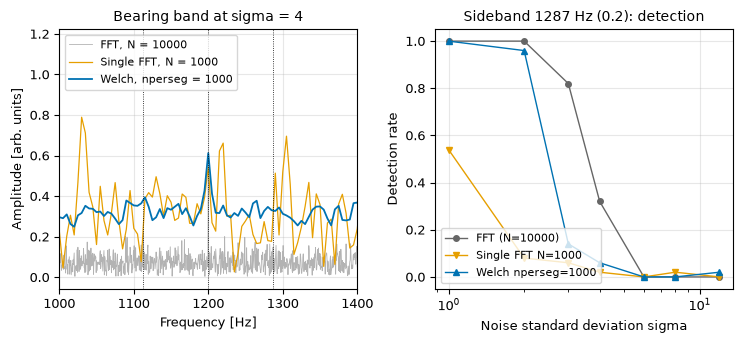

[saved] figures/13_welch_averaging.png


In [14]:
def welch_amplitude(x, fs_, nperseg, overlap=0.5, window="hann"):
    """Return (freqs, amplitude) of the Welch-averaged spectrum."""
    f_, p_ = signal.welch(x, fs=fs_, window=window, nperseg=nperseg,
                          noverlap=int(nperseg * overlap), scaling="spectrum")
    return f_, np.sqrt(2.0 * p_)


def detection_rate_spec(case, f_sig, sigma, n_runs, spec_fn):
    """Detection rate (as in Step 6) using an arbitrary spectrum function."""
    hits = 0
    for _ in range(n_runs):
        f_, a_ = spec_fn(MAKERS[case](sigma=sigma))
        d_ = f_[1] - f_[0]
        mask = np.ones(len(a_), dtype=bool)
        for fk_, _, _ in injected_components(case):
            k_ = int(round(fk_ / d_))
            mask[max(k_ - 2, 0):k_ + 3] = False
        hits += amp_at(a_, f_sig, d_) > a_[mask].max()
    return hits / n_runs


spec_fns = {"FFT (N=10000)": lambda x_: amplitude_spectrum(x_, fs)}
for npseg in CFG["welch_nperseg"]:
    spec_fns[f"Single FFT N={npseg}"] = (
        lambda x_, n_=npseg: amplitude_spectrum(x_[:n_], fs, window="hann"))
    spec_fns[f"Welch nperseg={npseg}"] = (
        lambda x_, n_=npseg: welch_amplitude(x_, fs, n_))
n_seg = {n_: 1 + (N - n_) // (n_ - n_ // 2) for n_ in CFG["welch_nperseg"]}
log("\nWelch averaging: Hann window, 50 % overlap")
for n_ in CFG["welch_nperseg"]:
    log(f"  nperseg = {n_}: {n_seg[n_]} segments, resolution {fs / n_:g} Hz")

sigma_w = 4.0
log(f"\nNoise-only floor at sigma = {sigma_w}: largest bin vs mean floor "
    f"({EXT_RUNS} runs)")
log(f"{'Spectrum':<24}{'CV of floor':>13}{'max/mean [dB]':>16}")
floor_stats = {}
for name_, fn_ in spec_fns.items():
    cv_, mx_ = [], []
    for _ in range(EXT_RUNS):
        f_, a_ = fn_(np.random.normal(0, sigma_w, N))
        a_ = a_[f_ > 100]
        cv_.append(a_.std() / a_.mean())
        mx_.append(20 * np.log10(a_.max() / a_.mean()))
    floor_stats[name_] = (np.mean(cv_), np.mean(mx_))
    log(f"{name_:<24}{np.mean(cv_):>13.3f}{np.mean(mx_):>16.2f}")

w_sigmas = [1.0, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0]
w_sigs = [("Bearing sideband 1287 Hz (0.2)", "Bearing fault",
           CFG["f_res"] + CFG["f_fault"]),
          ("Misalign. 0.5x (0.15)", "Misalignment", 0.5 * CFG["f_r"])]
w_det = {n_: np.array([[detection_rate_spec(c_, f_, s_, runs, fn_)
                        for s_ in w_sigmas] for _, c_, f_ in w_sigs])
         for n_, fn_ in spec_fns.items()}
log(f"\nDetection rate vs noise sigma ({runs} runs per point)")
log(f"{'Signature / spectrum':<46}" + "".join(f"{s_:>6g}" for s_ in w_sigmas))
for j_, (sname_, _, _) in enumerate(w_sigs):
    for n_ in spec_fns:
        log(f"{sname_[:22] + ' | ' + n_:<46}"
            + "".join(f"{v_:>6.2f}" for v_ in w_det[n_][j_]))

x_w = make_bearing(sigma=sigma_w)
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.5))
f1_, a1_ = amplitude_spectrum(x_w, fs)
f2_, a2_ = welch_amplitude(x_w, fs, CFG["welch_nperseg"][1])
f3_, a3_ = amplitude_spectrum(x_w[:CFG["welch_nperseg"][1]], fs, window="hann")
axes[0].plot(f1_, a1_, color="0.7", lw=0.6, label="FFT, N = 10000")
axes[0].plot(f3_, a3_, color="#E69F00", lw=0.9,
             label=f"Single FFT, N = {CFG['welch_nperseg'][1]}")
axes[0].plot(f2_, a2_, color="#0072B2", lw=1.3,
             label=f"Welch, nperseg = {CFG['welch_nperseg'][1]}")
for m_ in (CFG["f_res"] - CFG["f_fault"], CFG["f_res"],
           CFG["f_res"] + CFG["f_fault"]):
    axes[0].axvline(m_, color="k", ls=":", lw=0.6)
axes[0].set_xlim(1000, 1400)
axes[0].set_xlabel("Frequency [Hz]")
axes[0].set_ylabel("Amplitude [arb. units]")
axes[0].set_title(f"Bearing band at sigma = {sigma_w:g}")
axes[0].legend(loc="upper left")
styles = {"FFT (N=10000)": ("0.4", "o"),
          "Single FFT N=1000": ("#E69F00", "v"),
          "Welch nperseg=1000": ("#0072B2", "^")}
for n_, (c_, m_) in styles.items():
    axes[1].plot(w_sigmas, w_det[n_][0], color=c_, marker=m_, ms=4, label=n_)
axes[1].set_xscale("log")
axes[1].set_xlabel("Noise standard deviation sigma")
axes[1].set_ylabel("Detection rate")
axes[1].set_title("Sideband 1287 Hz (0.2): detection")
axes[1].legend(loc="lower left")
fig.tight_layout()
save_fig(fig, "13_welch_averaging.png")

## Step 10 - Short-time Fourier transform: a fault that starts mid-record
The FFT assumes a stationary signal. Here the machine is healthy for the first
second and imbalanced (1x amplitude 1.0 to 2.5) for the second half. A single FFT
reports one blended 1x amplitude and no timing; a hand-written STFT (Hann
windows, hop 100 samples) shows *when* the change happens. Longer windows give
finer frequency resolution but blur the transition: the fixed time-frequency trade-off.

In [15]:
def stft_amplitude(x, fs_, win_len, hop, window="hann"):
    """Hand-written STFT: return (frame-centre times, freqs, amplitude [f, t])."""
    w_ = signal.get_window(window, win_len)
    starts = np.arange(0, len(x) - win_len + 1, hop)
    frames = np.stack([x[s_:s_ + win_len] * w_ for s_ in starts])
    amp_ = 2.0 * np.abs(np.fft.rfft(frames, axis=1)) / np.sum(w_)
    return (starts + win_len / 2) / fs_, np.fft.rfftfreq(win_len, 1 / fs_), amp_.T


def make_onset(cfg=CFG, t_onset=None):
    """Healthy for t < t_onset, imbalance afterwards (+ noise)."""
    t_ = time_axis(cfg)
    t_on = cfg["onset_time"] if t_onset is None else t_onset
    a1_ = np.where(t_ >= t_on, cfg["imb_a1"], cfg["healthy_amps"][0])
    _, a2_, a3_ = cfg["healthy_amps"]
    return add_noise(harmonic_signal(t_, cfg, a1_, a2_, a3_), cfg["sigma"])


Fault onset at t = 1.0 s (1x: 1.0 -> 2.5)
  Single FFT of the whole record: 1x amplitude = 1.746 (time average of the two levels = 1.750); no timing information
  Window  Win [s]  Bin [Hz]  1x before  1x after  10-90 % rise [s]  Onset est. [s]
     200    0.040      25.0      1.004     2.486             0.020           1.020
     500    0.100      10.0      1.008     2.485             0.040           1.010
    1000    0.200       5.0      1.015     2.483             0.100           1.020


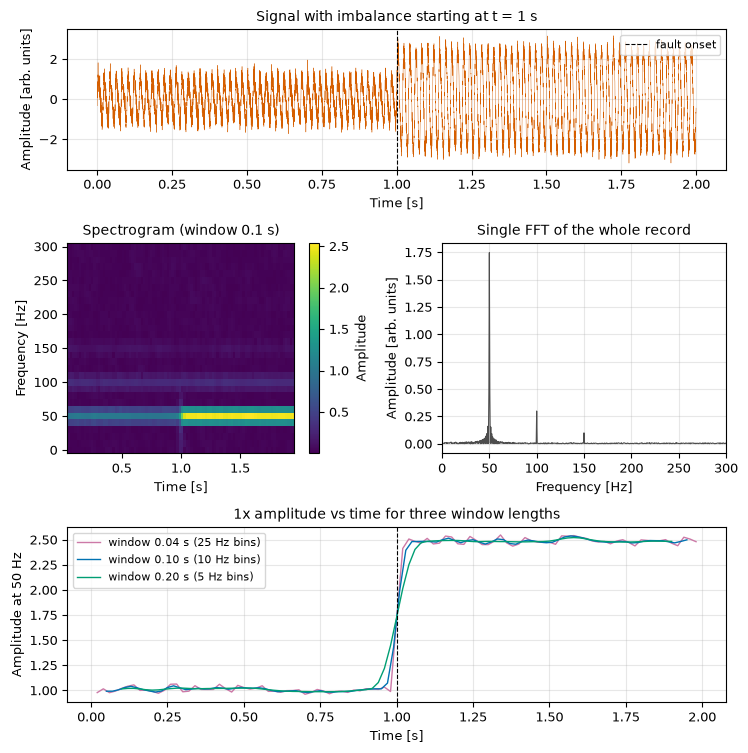

[saved] figures/14_stft_onset.png


In [16]:
x_on = make_onset()
t_on = CFG["onset_time"]
_, a_full = amplitude_spectrum(x_on, fs)
log(f"\nFault onset at t = {t_on} s (1x: {CFG['healthy_amps'][0]} -> "
    f"{CFG['imb_a1']})")
log(f"  Single FFT of the whole record: 1x amplitude = "
    f"{amp_at(a_full, fr, df):.3f} (time average of the two levels = "
    f"{(CFG['healthy_amps'][0] + CFG['imb_a1']) / 2:.3f}); no timing information")
log(f"{'Window':>8}{'Win [s]':>9}{'Bin [Hz]':>10}{'1x before':>11}"
    f"{'1x after':>10}{'10-90 % rise [s]':>18}{'Onset est. [s]':>16}")
tracks = {}
for L_ in CFG["stft_lens"]:
    t_c, f_s, A_ = stft_amplitude(x_on, fs, L_, CFG["stft_hop"])
    trk = A_[int(round(fr / (fs / L_)))]
    lo_ = np.median(trk[t_c < t_on - L_ / fs])
    hi_ = np.median(trk[t_c > t_on + L_ / fs])
    t10 = t_c[np.argmax(trk >= lo_ + 0.1 * (hi_ - lo_))]
    t90 = t_c[np.argmax(trk >= lo_ + 0.9 * (hi_ - lo_))]
    t50 = t_c[np.argmax(trk >= lo_ + 0.5 * (hi_ - lo_))]
    tracks[L_] = (t_c, trk)
    log(f"{L_:>8}{L_ / fs:>9.3f}{fs / L_:>10.1f}{lo_:>11.3f}{hi_:>10.3f}"
        f"{t90 - t10:>18.3f}{t50:>16.3f}")

t_c, f_s, A_s = stft_amplitude(x_on, fs, 500, CFG["stft_hop"])
fig = plt.figure(figsize=(7.5, 7.6))
gs = fig.add_gridspec(3, 2, height_ratios=[0.8, 1.2, 1])
ax = fig.add_subplot(gs[0, :])
ax.plot(t, x_on, color=COLORS["Imbalance"], lw=0.3)
ax.axvline(t_on, color="k", ls="--", lw=0.8, label="fault onset")
ax.set_title("Signal with imbalance starting at t = 1 s")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Amplitude [arb. units]")
ax.legend(loc="upper right")
ax = fig.add_subplot(gs[1, 0])
sel_f = f_s <= 300
im = ax.pcolormesh(t_c, f_s[sel_f], A_s[sel_f], shading="auto", cmap="viridis")
ax.set_title("Spectrogram (window 0.1 s)")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Frequency [Hz]")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Amplitude")
ax = fig.add_subplot(gs[1, 1])
ax.plot(f_axis, a_full, color="0.3", lw=0.8)
ax.set_xlim(0, 300)
ax.set_title("Single FFT of the whole record")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Amplitude [arb. units]")
ax = fig.add_subplot(gs[2, :])
for L_, c_ in zip(CFG["stft_lens"], ["#CC79A7", "#0072B2", "#009E73"]):
    ax.plot(*tracks[L_], color=c_, label=f"window {L_ / fs:.2f} s "
            f"({fs / L_:g} Hz bins)")
ax.axvline(t_on, color="k", ls="--", lw=0.8)
ax.set_title("1x amplitude vs time for three window lengths")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Amplitude at 50 Hz")
ax.legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "14_stft_onset.png")

## Step 11 - Drifting shaft speed and order tracking
If the speed drifts, f_r(t) = f0 + (f1 - f0) t / T and the phase is the integral of
f_r. Each harmonic k sweeps from k f0 to k f1, so a fixed-length FFT smears it over
many bins and the peak height falls. **Order tracking** resamples the signal at
equal shaft-angle steps (here using the known speed profile as a stand-in for a
tachometer), so the harmonics become fixed orders again and sharp peaks return.
The ramp 50 -> 56 Hz gives exactly 106 revolutions, so every order (including 0.5x) lands on a bin.

In [17]:
def make_variable_speed(cfg=CFG, noise=True):
    """Misalignment signal with linearly drifting speed; return (x, revs(t))."""
    t_ = time_axis(cfg)
    f0_, f1_ = cfg["speed_ramp"]
    revs = f0_ * t_ + (f1_ - f0_) / (2 * cfg["T"]) * t_ ** 2
    ph = 2 * np.pi * revs
    a1_ = cfg["healthy_amps"][0]
    x = (a1_ * np.sin(ph) + cfg["mis_a2"] * np.sin(2 * ph)
         + cfg["mis_a3"] * np.sin(3 * ph) + cfg["mis_a_half"] * np.sin(0.5 * ph))
    return (add_noise(x, cfg["sigma"]) if noise else x), revs


def order_track(x, revs, t_, n_out=None):
    """Resample x to equal angle steps; return (x_u, samples per rev)."""
    n_out = len(x) if n_out is None else n_out
    r_tot = CFG["speed_ramp"][0] * CFG["T"] + (CFG["speed_ramp"][1]
            - CFG["speed_ramp"][0]) * CFG["T"] / 2        # revs in [0, T]
    t_u = np.interp(np.arange(n_out) * (r_tot / n_out), revs, t_)
    return CubicSpline(t_, x)(t_u), n_out / r_tot


Variable speed: 50 -> 56 Hz over 2.0 s (106 revolutions); misalignment amplitudes
Harmonic   Injected  Const-speed FFT  Drifting FFT (max)  Bins > 0.05  Order spectrum
0.5x          0.150            0.149               0.078            5           0.150
1x            1.000            0.999               0.356           17           0.997
2x            1.200            1.195               0.299           29           1.200
3x            0.800            0.806               0.163           39           0.802


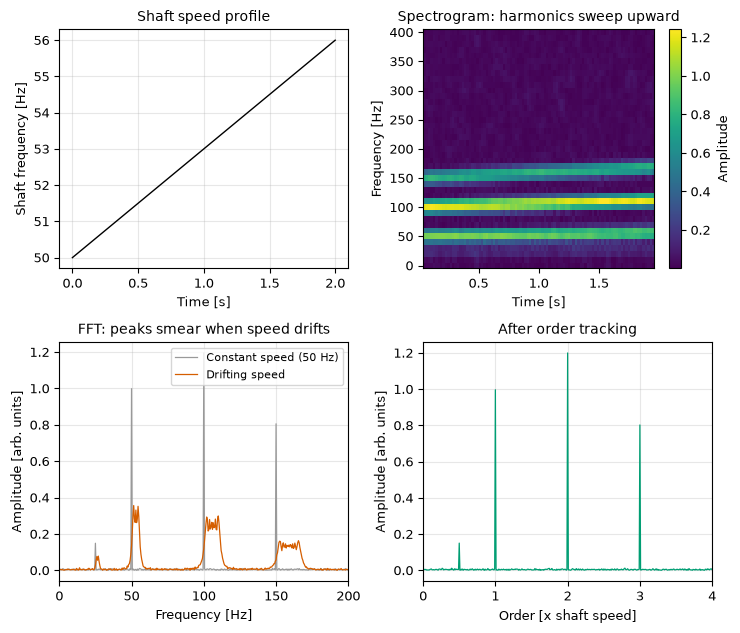

[saved] figures/15_variable_speed.png


In [18]:
x_vs, revs_vs = make_variable_speed()
x_u, spr = order_track(x_vs, revs_vs, t)
f_vs, a_vs = amplitude_spectrum(x_vs, fs)
o_ax, a_ord = amplitude_spectrum(x_u, spr)
f0_, f1_ = CFG["speed_ramp"]
d_ord = o_ax[1]
log(f"\nVariable speed: {f0_:g} -> {f1_:g} Hz over {CFG['T']} s "
    f"({(f0_ + f1_) / 2 * CFG['T']:.0f} revolutions); misalignment amplitudes")
log(f"{'Harmonic':<10}{'Injected':>9}{'Const-speed FFT':>17}"
    f"{'Drifting FFT (max)':>20}{'Bins > 0.05':>13}{'Order spectrum':>16}")
for k_, ak_ in [(0.5, CFG["mis_a_half"]), (1, CFG["healthy_amps"][0]),
                (2, CFG["mis_a2"]), (3, CFG["mis_a3"])]:
    b_lo, b_hi = k_ * f0_ - 1, k_ * f1_ + 1
    in_b = (f_vs >= b_lo) & (f_vs <= b_hi)
    log(f"{str(k_) + 'x':<10}{ak_:>9.3f}"
        f"{amp_at(spectra['Misalignment'], k_ * fr, df):>17.3f}"
        f"{a_vs[in_b].max():>20.3f}{int((a_vs[in_b] > 0.05).sum()):>13d}"
        f"{amp_at(a_ord, k_, d_ord):>16.3f}")

t_c, f_s, A_s = stft_amplitude(x_vs, fs, 500, CFG["stft_hop"])
fig, axes = plt.subplots(2, 2, figsize=(7.5, 6.4))
ax = axes[0, 0]
ax.plot(t, f0_ + (f1_ - f0_) * t / CFG["T"], color="k")
ax.set_title("Shaft speed profile")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Shaft frequency [Hz]")
ax = axes[0, 1]
sel_f = f_s <= 400
im = ax.pcolormesh(t_c, f_s[sel_f], A_s[sel_f], shading="auto", cmap="viridis")
ax.set_title("Spectrogram: harmonics sweep upward")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Frequency [Hz]")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Amplitude")
ax = axes[1, 0]
ax.plot(f_axis, spectra["Misalignment"], color="0.6", lw=0.9,
        label="Constant speed (50 Hz)")
ax.plot(f_vs, a_vs, color="#D55E00", lw=0.9, label="Drifting speed")
ax.set_xlim(0, 200)
ax.set_title("FFT: peaks smear when speed drifts")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Amplitude [arb. units]")
ax.legend(loc="upper right")
ax = axes[1, 1]
ax.plot(o_ax, a_ord, color="#009E73", lw=0.9)
ax.set_xlim(0, 4)
ax.set_title("After order tracking")
ax.set_xlabel("Order [x shaft speed]")
ax.set_ylabel("Amplitude [arb. units]")
fig.tight_layout()
save_fig(fig, "15_variable_speed.png")

## Step 12 - Filter comparison
Candidate 400 Hz low-pass filters, applied causally (single pass) so that delay
and phase effects are visible: Butterworth (orders 2-8), Chebyshev type I (4th
order, 1 dB ripple), Bessel (4th order) and a 101-tap Hamming-window FIR. White
noise passed through each gives the noise reduction.

In [19]:
def lowpass_candidates(cfg=CFG):
    """Return dict name -> ('sos'|'fir', coefficients) for 400 Hz low-passes."""
    fs_, fc_ = cfg["fs"], cfg["lp_cut"]
    c = {"Butterworth n=4": ("sos", signal.butter(4, fc_, fs=fs_, output="sos")),
         "Chebyshev I n=4 (1 dB)": ("sos", signal.cheby1(
             4, 1, fc_, fs=fs_, output="sos")),
         "Bessel n=4": ("sos", signal.bessel(
             4, fc_, fs=fs_, norm="mag", output="sos")),
         "FIR 101 taps (Hamming)": ("fir", signal.firwin(
             101, fc_, fs=fs_, window="hamming"))}
    for n_ in (2, 6, 8):
        c[f"Butterworth n={n_}"] = ("sos", signal.butter(
            n_, fc_, fs=fs_, output="sos"))
    return c


def filter_response(kc, worN, fs_):
    """Return (freqs, complex response) for an sos or FIR filter."""
    kind, c = kc
    if kind == "sos":
        return signal.sosfreqz(c, worN=worN, fs=fs_)
    return signal.freqz(c, 1, worN=worN, fs=fs_)


def apply_causal(kc, x):
    """Single-pass (causal) filtering."""
    kind, c = kc
    return signal.sosfilt(c, x) if kind == "sos" else signal.lfilter(c, 1, x)


def group_delay_ms(kc, freqs, fs_):
    """Group delay [ms] at the given frequencies [Hz]."""
    kind, c = kc
    b_, a_ = signal.sos2tf(c) if kind == "sos" else (c, 1)
    _, gd = signal.group_delay((b_, a_), w=2 * np.pi * np.asarray(freqs) / fs_)
    return gd / fs_ * 1e3


Low-pass filter comparison (fc = 400 Hz, causal single pass)
Filter                       50 Hz  100 Hz  150 Hz -3 dB [Hz]   800 Hz  Noise red.  Delay 50  dDelay
                              [dB]    [dB]    [dB]                [dB]        [dB]      [ms]    [ms]
Butterworth n=4              -0.00   -0.00   -0.00        400    -26.5        7.87      1.03    0.07
Chebyshev I n=4 (1 dB)       -0.80   -0.33   -0.00        420    -36.6        8.11      1.12    0.38
Bessel n=4                   -0.04   -0.17   -0.38        399    -15.2        7.85      0.82    0.01
FIR 101 taps (Hamming)        0.03   -0.00    0.03        380    -64.0        8.17     10.00    0.00
Butterworth n=2              -0.00   -0.02   -0.08        400    -13.4        7.62      0.56    0.06
Butterworth n=6              -0.00   -0.00   -0.00        400    -39.7        7.92      1.51    0.09
Butterworth n=8              -0.00   -0.00   -0.00        400    -52.9        7.94      2.01    0.11
(dDelay = group delay at 150 

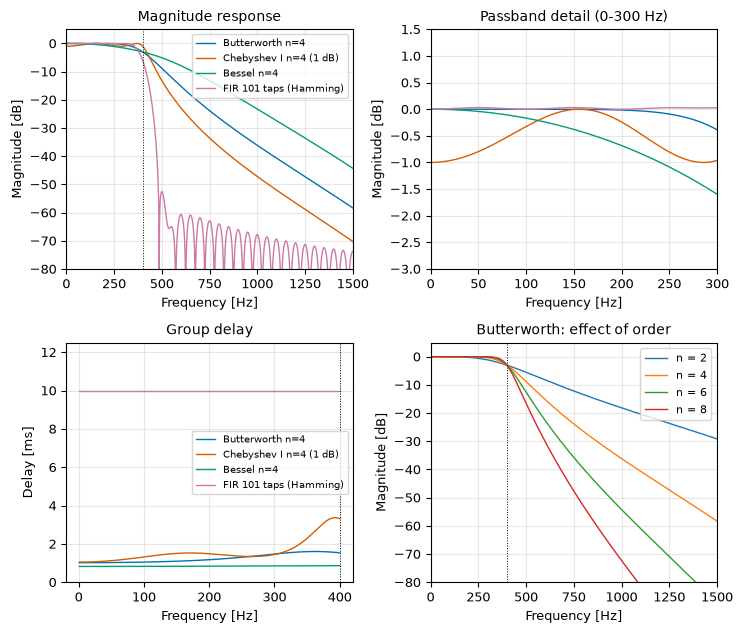

[saved] figures/16_filter_comparison.png


In [20]:
cands = lowpass_candidates()
w_grid = np.linspace(0, fs / 2, 5001)
white = np.random.normal(size=200000)
log("\nLow-pass filter comparison (fc = 400 Hz, causal single pass)")
log(f"{'Filter':<26}{'50 Hz':>8}{'100 Hz':>8}{'150 Hz':>8}{'-3 dB [Hz]':>11}"
    f"{'800 Hz':>9}{'Noise red.':>12}{'Delay 50':>10}{'dDelay':>8}")
log(f"{'':<26}{'[dB]':>8}{'[dB]':>8}{'[dB]':>8}{'':>11}{'[dB]':>9}{'[dB]':>12}"
    f"{'[ms]':>10}{'[ms]':>8}")
resp = {}
for name_, kc_ in cands.items():
    w_, h_ = filter_response(kc_, w_grid, fs)
    mag_ = 20 * np.log10(np.maximum(np.abs(h_), 1e-12))
    resp[name_] = (w_, mag_)
    g_ = lambda f_: mag_[np.argmin(np.abs(w_ - f_))]  # noqa: E731
    f3_ = w_[np.argmax(mag_ < -3.0)]
    y_ = apply_causal(kc_, white)[2000:]
    red_ = 10 * np.log10(np.var(white[2000:]) / np.var(y_))
    gd_ = group_delay_ms(kc_, [50, 150], fs)
    log(f"{name_:<26}{g_(50):>8.2f}{g_(100):>8.2f}{g_(150):>8.2f}{f3_:>11.0f}"
        f"{g_(800):>9.1f}{red_:>12.2f}{gd_[0]:>10.2f}{gd_[1] - gd_[0]:>8.2f}")
log("(dDelay = group delay at 150 Hz minus at 50 Hz: waveform distortion; "
    "FIR delay is (101-1)/2/fs = 10 ms, constant)")

fig, axes = plt.subplots(2, 2, figsize=(7.5, 6.4))
main4 = ["Butterworth n=4", "Chebyshev I n=4 (1 dB)", "Bessel n=4",
         "FIR 101 taps (Hamming)"]
cols4 = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
for nm_, c_ in zip(main4, cols4):
    axes[0, 0].plot(*resp[nm_], color=c_, label=nm_)
    axes[0, 1].plot(*resp[nm_], color=c_, label=nm_)
    w_, _ = filter_response(cands[nm_], np.linspace(1, 400, 400), fs)
    axes[1, 0].plot(np.linspace(1, 400, 400),
                    group_delay_ms(cands[nm_], np.linspace(1, 400, 400), fs),
                    color=c_, label=nm_)
for n_ in (2, 4, 6, 8):
    axes[1, 1].plot(*resp[f"Butterworth n={n_}"], label=f"n = {n_}")
axes[0, 0].set_ylim(-80, 5)
axes[0, 0].set_xlim(0, 1500)
axes[0, 0].set_title("Magnitude response")
axes[0, 1].set_ylim(-3, 1.5)
axes[0, 1].set_xlim(0, 300)
axes[0, 1].set_title("Passband detail (0-300 Hz)")
axes[1, 0].set_title("Group delay")
axes[1, 0].set_ylabel("Delay [ms]")
axes[1, 1].set_ylim(-80, 5)
axes[1, 1].set_xlim(0, 1500)
axes[1, 1].set_title("Butterworth: effect of order")
for ax_ in axes.ravel():
    ax_.set_xlabel("Frequency [Hz]")
    ax_.axvline(CFG["lp_cut"], color="k", ls=":", lw=0.7)
for ax_ in (axes[0, 0], axes[0, 1], axes[1, 1]):
    ax_.set_ylabel("Magnitude [dB]")
axes[0, 0].legend(loc="upper right", fontsize=7)
axes[1, 0].set_ylim(0, 12.5)
axes[1, 0].legend(loc="center right", fontsize=7)
axes[1, 1].legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "16_filter_comparison.png")

## Step 13 - Severity sweep (trending)
In predictive maintenance the amplitude at a fault frequency is *trended* over time.
We raise the imbalance 1x amplitude from 1.0 to 4.0 and check that the measured
1x amplitude follows it linearly, 20 noise realisations per point.


Severity sweep (imbalance 1x amplitude), 20 runs per point
 Injected 1x     Measured 1x             RMS  RMS theory
        1.00    0.9996+/-0.0038    0.7824+/-0.0025      0.7826
        1.50    1.5000+/-0.0032    1.1127+/-0.0024      1.1124
        2.00    1.9982+/-0.0036    1.4521+/-0.0027      1.4534
        2.50    2.5002+/-0.0031    1.7993+/-0.0020      1.7993
        3.00    2.9997+/-0.0028    2.1475+/-0.0020      2.1477
        3.50    3.4997+/-0.0026    2.4972+/-0.0018      2.4975
        4.00    3.9999+/-0.0040    2.8482+/-0.0028      2.8482
Linear fit of measured 1x vs injected: slope = 1.0001, intercept = -0.0007


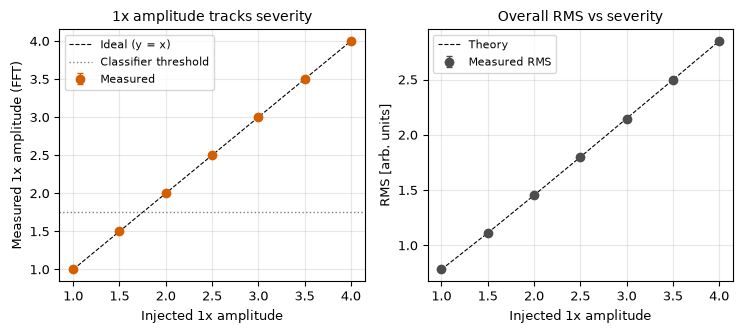

[saved] figures/17_severity_sweep.png


In [21]:
sev = CFG["sev_amps"]
sev_meas, sev_rms = [], []
for a_ in sev:
    cfg_s = dict(CFG, imb_a1=a_)
    am_, rm_ = [], []
    for _ in range(EXT_RUNS):
        x_ = make_imbalance(cfg_s)
        am_.append(amp_at(amplitude_spectrum(x_, fs)[1], fr, df))
        rm_.append(np.sqrt(np.mean(x_ ** 2)))
    sev_meas.append((np.mean(am_), np.std(am_, ddof=1)))
    sev_rms.append((np.mean(rm_), np.std(rm_, ddof=1)))
a2_, a3_ = CFG["healthy_amps"][1:]
rms_theory = [np.sqrt((a_ ** 2 + a2_ ** 2 + a3_ ** 2) / 2 + CFG["sigma"] ** 2)
              for a_ in sev]
slope, icpt = np.polyfit(sev, [m_[0] for m_ in sev_meas], 1)
log(f"\nSeverity sweep (imbalance 1x amplitude), {EXT_RUNS} runs per point")
log(f"{'Injected 1x':>12}{'Measured 1x':>16}{'RMS':>16}{'RMS theory':>12}")
for a_, m_, r_, rt_ in zip(sev, sev_meas, sev_rms, rms_theory):
    log(f"{a_:>12.2f}{m_[0]:>10.4f}+/-{m_[1]:.4f}{r_[0]:>10.4f}+/-{r_[1]:.4f}"
        f"{rt_:>12.4f}")
log(f"Linear fit of measured 1x vs injected: slope = {slope:.4f}, "
    f"intercept = {icpt:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4))
axes[0].errorbar(sev, [m_[0] for m_ in sev_meas], [m_[1] for m_ in sev_meas],
                 fmt="o", color=COLORS["Imbalance"], capsize=2, label="Measured")
axes[0].plot(sev, sev, "k--", lw=0.8, label="Ideal (y = x)")
axes[0].axhline(CFG["clf"]["imb_a1"], color="0.5", ls=":",
                label="Classifier threshold")
axes[0].set_xlabel("Injected 1x amplitude")
axes[0].set_ylabel("Measured 1x amplitude (FFT)")
axes[0].set_title("1x amplitude tracks severity")
axes[0].legend(loc="upper left")
axes[1].errorbar(sev, [r_[0] for r_ in sev_rms], [r_[1] for r_ in sev_rms],
                 fmt="o", color="0.3", capsize=2, label="Measured RMS")
axes[1].plot(sev, rms_theory, "k--", lw=0.8, label="Theory")
axes[1].set_xlabel("Injected 1x amplitude")
axes[1].set_ylabel("RMS [arb. units]")
axes[1].set_title("Overall RMS vs severity")
axes[1].legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "17_severity_sweep.png")

## Step 14 - Combined faults
Real machines can have more than one fault. The toy classifier of Step 5 returns a
*single* label with a fixed rule priority, so it cannot represent two faults. A
multi-label version (`detect_flags`) tests each rule independently.

In [22]:
def make_combined(cfg=CFG, imbalance=False, misalignment=False, bearing=False,
                  noise=True, sigma=None):
    """Healthy signal with any combination of the three fault models."""
    t_ = time_axis(cfg)
    a1_, a2_, a3_ = cfg["healthy_amps"]
    a_half_ = 0.0
    if imbalance:
        a1_ = cfg["imb_a1"]
    if misalignment:
        a2_, a3_, a_half_ = cfg["mis_a2"], cfg["mis_a3"], cfg["mis_a_half"]
    x = harmonic_signal(t_, cfg, a1_, a2_, a3_, a_half_)
    if bearing:
        x = x + bearing_term(t_, cfg)
    return add_noise(x, cfg["sigma"] if sigma is None else sigma) if noise else x


def detect_flags(amp, cfg=CFG):
    """Multi-label rules: return the tuple of fault names whose rule fires."""
    c, df_, fr_ = cfg["clf"], cfg["df"], cfg["f_r"]
    flags = []
    if min(amp_at(amp, cfg["f_res"] - cfg["f_fault"], df_),
           amp_at(amp, cfg["f_res"] + cfg["f_fault"], df_)) > c["bearing_sideband"]:
        flags.append("Bearing fault")
    if amp_at(amp, 2 * fr_, df_) > c["mis_a2"] and amp_at(
            amp, 3 * fr_, df_) > c["mis_a3"]:
        flags.append("Misalignment")
    if amp_at(amp, fr_, df_) > c["imb_a1"]:
        flags.append("Imbalance")
    return tuple(flags)


Combined faults, 50 runs per class, sigma = 0.25
True class                Single-label predictions                             Multi-label exact
Healthy                   {'Healthy': 50}                                                  100 %
Imbalance                 {'Imbalance': 50}                                                100 %
Misalignment              {'Misalignment': 50}                                             100 %
Bearing fault             {'Bearing fault': 50}                                            100 %
Imbalance + Misalignment  {'Misalignment': 50}                                             100 %
Imbalance + Bearing       {'Bearing fault': 50}                                            100 %
Misalignment + Bearing    {'Bearing fault': 50}                                            100 %


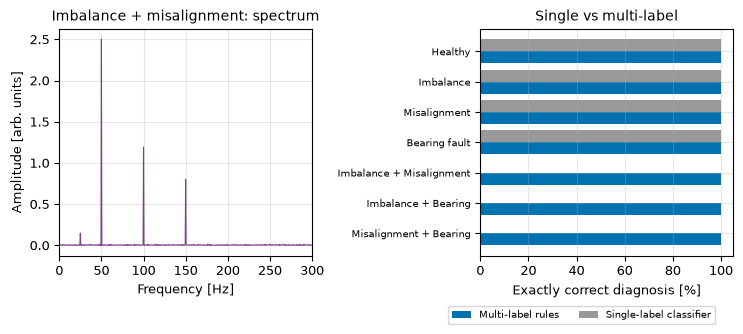

[saved] figures/18_combined_faults.png


In [23]:
combo = [("Healthy", dict(), ()),
         ("Imbalance", dict(imbalance=True), ("Imbalance",)),
         ("Misalignment", dict(misalignment=True), ("Misalignment",)),
         ("Bearing fault", dict(bearing=True), ("Bearing fault",)),
         ("Imbalance + Misalignment", dict(imbalance=True, misalignment=True),
          ("Misalignment", "Imbalance")),
         ("Imbalance + Bearing", dict(imbalance=True, bearing=True),
          ("Bearing fault", "Imbalance")),
         ("Misalignment + Bearing", dict(misalignment=True, bearing=True),
          ("Bearing fault", "Misalignment"))]
log(f"\nCombined faults, {runs} runs per class, sigma = {CFG['sigma']}")
log(f"{'True class':<26}{'Single-label predictions':<52}{'Multi-label exact':>18}")
combo_res = []
for name_, kw_, truth_ in combo:
    single, exact = {}, 0
    for _ in range(runs):
        _, a_ = amplitude_spectrum(make_combined(**kw_), fs)
        lab_ = classify(a_)
        single[lab_] = single.get(lab_, 0) + 1
        exact += set(detect_flags(a_)) == set(truth_)
    combo_res.append((name_, single, exact / runs))
    log(f"{name_:<26}{str(single):<52}{100 * exact / runs:>16.0f} %")

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.5))
f_c, a_c = amplitude_spectrum(make_combined(imbalance=True, misalignment=True), fs)
axes[0].plot(f_c, a_c, color="#7f3c8d", lw=0.8)
axes[0].set_xlim(0, 300)
axes[0].set_title("Imbalance + misalignment: spectrum")
axes[0].set_xlabel("Frequency [Hz]")
axes[0].set_ylabel("Amplitude [arb. units]")
names_c = [r_[0] for r_ in combo_res]
ypos = np.arange(len(names_c))
axes[1].barh(ypos + 0.2, [100 * r_[2] for r_ in combo_res], 0.4,
             color="#0072B2", label="Multi-label rules")
axes[1].barh(ypos - 0.2, [100 * (r_[1].get(r_[0], 0) / runs) for r_ in combo_res],
             0.4, color="0.6", label="Single-label classifier")
axes[1].set_yticks(ypos)
axes[1].set_yticklabels(names_c, fontsize=7)
axes[1].invert_yaxis()
axes[1].set_xlabel("Exactly correct diagnosis [%]")
axes[1].set_title("Single vs multi-label")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=2,
               fontsize=7)
fig.tight_layout()
save_fig(fig, "18_combined_faults.png")

## Step 15 - Cross-checks of the FFT
(i) A direct O(N^2) DFT matrix product must equal `np.fft.fft` to rounding
error. (ii) Parseval's theorem: the energy in time equals the energy in
frequency. (iii) Execution time versus N shows O(N^2) against O(N log N).
(Timings depend on the machine and change from run to run.)


FFT cross-checks
  Direct DFT vs np.fft.fft (N = 2000): max |difference| = 9.88e-11 (max |X| = 1000.8)
  Parseval             sum x^2   sum |X|^2 / N   rel. error   one-sided sum  rel. error
  Healthy             6146.874        6146.874      1.5e-16        6146.874     0.0e+00
  Imbalance          32522.401       32522.401      0.0e+00       32522.401     0.0e+00
  Misalignment       16101.115       16101.115      3.4e-16       16101.115     2.3e-16
  Bearing fault       7771.253        7771.253      3.5e-16        7771.253     3.5e-16


  Timing at N = 2048: direct DFT 67.4 ms, FFT 0.014 ms (4672x faster)
  Fitted log-log slopes: direct DFT 1.98 (N = 128-2048), FFT 1.19 (N = 2^15-2^20; theory: 2 and slightly above 1)


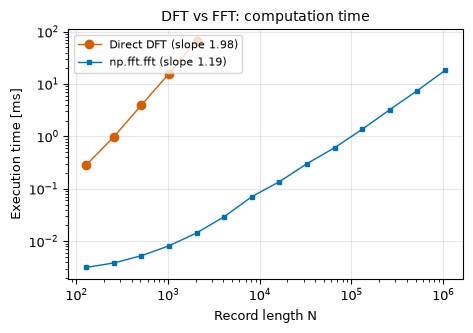

[saved] figures/19_dft_vs_fft_timing.png


In [24]:
def dft_direct(x):
    """Direct DFT: X[k] = sum_n x[n] exp(-2j pi k n / N), O(N^2)."""
    n_ = len(x)
    k_ = np.arange(n_)
    return np.exp(-2j * np.pi * np.outer(k_, k_) / n_) @ x


x_chk = signals["Healthy"][:2000]
err_dft = np.max(np.abs(dft_direct(x_chk) - np.fft.fft(x_chk)))
log(f"\nFFT cross-checks")
log(f"  Direct DFT vs np.fft.fft (N = 2000): max |difference| = {err_dft:.2e} "
    f"(max |X| = {np.max(np.abs(np.fft.fft(x_chk))):.1f})")
log(f"{'  Parseval':<16}{'sum x^2':>14}{'sum |X|^2 / N':>16}{'rel. error':>13}"
    f"{'one-sided sum':>16}{'rel. error':>12}")
for case in CASES:
    x_ = signals[case]
    e_t = np.sum(x_ ** 2)
    e_f = np.sum(np.abs(np.fft.fft(x_)) ** 2) / N
    a_ = spectra[case]
    p_one = (a_[0] ** 2 + np.sum(a_[1:-1] ** 2) / 2 + a_[-1] ** 2) * N
    log(f"  {case:<14}{e_t:>14.3f}{e_f:>16.3f}{abs(e_t - e_f) / e_t:>13.1e}"
        f"{p_one:>16.3f}{abs(e_t - p_one) / e_t:>12.1e}")

sizes = [128, 256, 512, 1024, 2048]
sizes_fft = [2 ** k_ for k_ in range(7, 21)]
t_dft, t_fft = [], []
for n_ in sizes:
    xs_ = np.random.randn(n_)
    t0_ = time.perf_counter()
    for _ in range(5):
        dft_direct(xs_)
    t_dft.append((time.perf_counter() - t0_) / 5)
for n_ in sizes_fft:
    xs_ = np.random.randn(n_)
    reps = max(3, int(2e6 // n_))
    t0_ = time.perf_counter()
    for _ in range(reps):
        np.fft.fft(xs_)
    t_fft.append((time.perf_counter() - t0_) / reps)
p_dft = np.polyfit(np.log(sizes), np.log(t_dft), 1)[0]
p_fft = np.polyfit(np.log(sizes_fft[-6:]), np.log(t_fft[-6:]), 1)[0]
i_2048 = sizes_fft.index(2048)
log(f"  Timing at N = 2048: direct DFT {1e3 * t_dft[-1]:.1f} ms, "
    f"FFT {1e3 * t_fft[i_2048]:.3f} ms ({t_dft[-1] / t_fft[i_2048]:.0f}x faster)")
log(f"  Fitted log-log slopes: direct DFT {p_dft:.2f} (N = 128-2048), "
    f"FFT {p_fft:.2f} (N = 2^15-2^20; theory: 2 and slightly above 1)")

fig, ax = plt.subplots(figsize=(4.8, 3.4))
ax.loglog(sizes, 1e3 * np.array(t_dft), "o-", color="#D55E00",
          label=f"Direct DFT (slope {p_dft:.2f})")
ax.loglog(sizes_fft, 1e3 * np.array(t_fft), "s-", ms=3, color="#0072B2",
          label=f"np.fft.fft (slope {p_fft:.2f})")
ax.set_xlabel("Record length N")
ax.set_ylabel("Execution time [ms]")
ax.set_title("DFT vs FFT: computation time")
ax.legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "19_dft_vs_fft_timing.png")

## Done
All figures are in `figures/`, the peak table in `results/peak_table.csv`.

In [25]:
log("\nAll figures saved to figures/ (200 dpi).")
(RES_DIR / "summary.txt").write_text("\n".join(LOG_LINES) + "\n")


All figures saved to figures/ (200 dpi).


17567